# QC0426 / VTI — Analysis

Analysis notebook for QC0426 (spxtr/measureme `sweep` data layout:
`data/<i>/data.tsv[.gz]` + `metadata.json`). This session's data ids start
at 0; there are no designated reference runs.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute
cells here. Measurement cells live on the measure notebook.

In [1]:
import os
import json

import numpy as np
import scipy.constants as cst
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

from sweep import sweep_load as sl
from pathlib import Path

%matplotlib inline

cst_e = cst.e
cst_h = cst.h
Rq = cst_h/cst_e**2

def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


def load1d(i):
    return np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv.gz"))

def load_meta(i):
    fp = open(os.path.join(file_path, "{:d}".format(i), "metadata.json"), "r")
    return json.load(fp)

def pretty_load(i):
    data = load1d(i)
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

def pretty_load2d(i):
    data = np.loadtxt(os.path.join(file_path, "{:d}".format(i), "data.tsv"))
    meta = load_meta(i)

    data_dict = {}
    for ind, col in enumerate(meta['columns']):
        data_dict[col] = data[:, ind]

    return data_dict

## (n, D) — capacitance-based convention

Density/displacement from areal gate capacitances (`calc_nD`), **not** the
toploader's `dtg/dbg` constant form. `n` comes out in SI (m^-2; multiply by
1e-16 for 10^12 cm^-2); `D` in V/nm.

In [2]:
cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D


# Device gate-stack constants — fill in per device (meters)
t_tg = 15.6e-9         # top-gate hBN thickness (geometry prior — calibrate)
t_bg = 12e-9           # back-gate hBN thickness (geometry prior — calibrate)
t_bgSiO2 = 0           # SiO2 term zeroed for QC0426 (n, D) — Si gate is screening

c_tg = calc_ctg(t_tg)
c_bg = calc_cbg(t_bg, t_bgSiO2)

## Fan re-plot pattern

On this rig the current channel is **`sr0` read through the Ithaco preamp**:
the explicit gain division `I = sr0_X / measurement_config['sr0_gain']` is
**mandatory** — skipping it inverts/rescales every R. (`sr0_gain` is negative,
e.g. -1e6.) The on-disk `plot.png` is only the live monitor; always re-form
R from the TSV.

In [ ]:
# PATTERN — Landau-fan re-plot (set the file id).
dat = sl.pload(file_path, <FILE_ID>)

n, D = calc_nD(dat['xs'][0], dat['xs'][1], c_tg, c_bg)
n_12cm = n * 1e-16  # 10^12 cm^-2
ys = dat['ys'][0]   # B (T)

# Current — explicit gain division is MANDATORY on this rig
curr = dat['sr0_X'] / dat['measurement_config']['sr0_gain']

r_xx = ['sr1_X', 'sr2_X']
r_xy = ['sr3_X']

nu = <NU>
nn = cst.e * ys * nu / cst.h * 1e-16  # filling-factor line n = nu·e·B/h, in 10^12 cm^-2

norm = mcolors.SymLogNorm(linthresh=50, vmin=0, vmax=100e3)
for r_xx_pair in r_xx:
    data = dat[r_xx_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='viridis', norm=norm)
    plt.colorbar(label='$R_{xx}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')

h_e2 = cst.h/cst.e**2
for r_xy_pair in r_xy:
    data = dat[r_xy_pair] / curr
    plt.figure()
    plt.pcolormesh(n_12cm, ys, data, cmap='seismic',
                   vmax=h_e2/nu, vmin=-h_e2/nu)
    plt.colorbar(label='$R_{xy}$ (Ohms)')
    plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
    plt.ylabel('$B$ (T)')
    plt.plot(nn, ys, '--')

plt.figure(dpi=240)
plt.pcolormesh(n_12cm, ys, curr*1e9, cmap='inferno')
plt.colorbar(label='I (nA)')
plt.xlabel('$n$ 10$^{12}$ (cm$^{-2}$)')
plt.ylabel('$B$ (T)')

## Filling-factor overlay pattern

In [ ]:
# PATTERN — filling-factor overlay: nu lines n = nu·e·B/h on the current fan
# axes (n axis in 10^12 cm^-2 → factor 1e-16 from SI m^-2).
for nu in [<NU_LIST>]:
    nn = cst.e * ys * nu / cst.h * 1e-16
    plt.plot(nn, ys, '--', lw=1, label=rf'$\nu = {nu}$')
plt.legend()

## (n, D) calibration — CNP-line slope (file_id 1, gatemap)

Per-channel CNP ridge extraction (smoothed argmax along TG, windowed to the continuous ridge, edge-clipped rows dropped) → linear fit → cap ratio `c_bg/c_tg = −slope`. Both Rxx channels agree (Δ ratio ≈ 0.006), and the fitted ratio reproduces the 15.6/12 nm geometry prior. **Two-tier provenance**: ratio data-calibrated; absolute scale geometry-prior (15.6 nm hBN), pending a quantum-Hall lever-arm upgrade from the fan. CNP at (TG,BG)≈(0,0) → D≈0 reachable; D_offset=0 (no feature located D=0 independently — stated assumption).

sr1 T3-T4: slope -1.3013  intercept +0.0668 V  c_bg/c_tg=1.301  RMS 56.2 mV  (rows 41/41)
sr2 B4-B5: slope -1.2951  intercept +0.0697 V  c_bg/c_tg=1.295  RMS 76.2 mV  (rows 41/41)


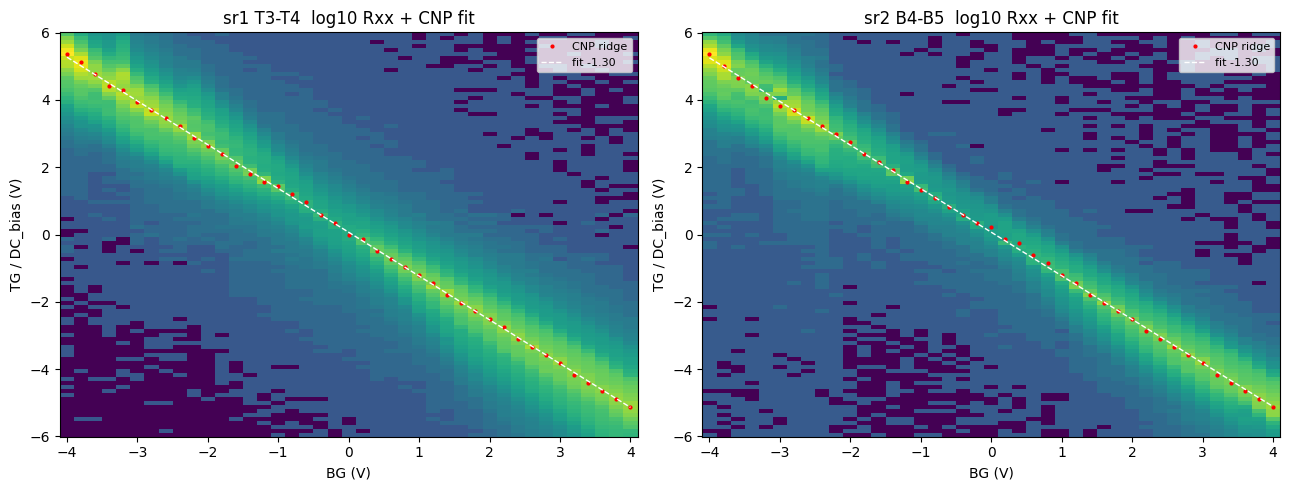


cross-channel ratio agreement: 1.301 vs 1.295
ADOPTED  c_bg/c_tg=1.298  c_tg=1.7027e-03  c_bg=2.2105e-03 F/m^2
         n_offset=-7.095e+14 m^-2  D_offset=0.0
provenance: RATIO data-calibrated (file_id 1); SCALE geometry prior (15.6 nm hBN), pending QH lever-arm upgrade from the fan
closure: max|n| on fitted ridge = 1.32e+14 m^-2 (0.013e12 cm^-2)
density lever (D=0): 2.126e+12 cm^-2 per V (TG, BG matched)


In [3]:
from scipy.ndimage import gaussian_filter1d

# --- load the 0 T gate map (file_id 1) ---
mD = load_meta(1); cols = mD['columns']; ci = {c: i for i, c in enumerate(cols)}
raw = load1d(1); nfast = 101; nr = raw.shape[0] // nfast
g = raw[:nr*nfast].reshape(nr, nfast, -1)
bg = g[:, 0, ci['k_bg_volt']]; tg = g[0, :, ci['DC_bias']]
I_bias = 5e-9

def ridge(col):
    """Smoothed-argmax CNP ridge per BG row, windowed to the continuous ridge
    (geometry-prior seed) and excluding edge-clipped rows."""
    R = np.abs(g[:, :, ci[col]]) / I_bias
    pred = -1.30 * bg; out = np.full(nr, np.nan)
    for r in range(nr):
        win = np.abs(tg - pred[r]) < 2.0
        j = np.where(win)[0][np.argmax(gaussian_filter1d(R[r], 2.0)[win])]
        if 1 < j < nfast - 2:
            out[r] = tg[j]
    return out, R

fits = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, (nm, col) in enumerate([('sr1 T3-T4', 'sr1_X'), ('sr2 B4-B5', 'sr2_X')]):
    rc, R = ridge(col); ok = ~np.isnan(rc)
    p = np.polyfit(bg[ok], rc[ok], 1); ratio = -p[0]
    rms = (rc[ok] - np.polyval(p, bg[ok])).std()
    fits[nm] = (p[0], p[1], ratio, rms)
    print(f"{nm}: slope {p[0]:.4f}  intercept {p[1]:+.4f} V  c_bg/c_tg={ratio:.3f}"
          f"  RMS {rms*1e3:.1f} mV  (rows {ok.sum()}/{nr})")
    ax[k].pcolormesh(bg, tg, np.log10(np.clip(R.T, 1, None)), shading='auto', cmap='viridis')
    ax[k].plot(bg[ok], rc[ok], 'r.', ms=4, label='CNP ridge')
    ax[k].plot(bg, np.polyval(p, bg), 'w--', lw=1, label=f'fit {p[0]:.2f}')
    ax[k].set_xlabel('BG (V)'); ax[k].set_ylabel('TG / DC_bias (V)')
    ax[k].set_title(f'{nm}  log10 Rxx + CNP fit'); ax[k].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

# --- adopt calibration: RATIO data-calibrated; SCALE geometry-prior ---
ratio = float(np.mean([fits[k][2] for k in fits]))
c_tg_cal = calc_ctg(15.6e-9)               # anchored to 15.6 nm hBN stack prior
c_bg_cal = ratio * c_tg_cal
b_int = fits['sr1 T3-T4'][1]
n_offset_cal = -calc_nD(b_int, 0, c_tg_cal, c_bg_cal)[0]
D_offset_cal = 0.0
print(f"\ncross-channel ratio agreement: {fits['sr1 T3-T4'][2]:.3f} vs {fits['sr2 B4-B5'][2]:.3f}")
print(f"ADOPTED  c_bg/c_tg={ratio:.3f}  c_tg={c_tg_cal:.4e}  c_bg={c_bg_cal:.4e} F/m^2")
print(f"         n_offset={n_offset_cal:.3e} m^-2  D_offset={D_offset_cal}")
print("provenance: RATIO data-calibrated (file_id 1); SCALE geometry prior (15.6 nm hBN),"
      " pending QH lever-arm upgrade from the fan")
tg_line = np.polyval([fits['sr1 T3-T4'][0], b_int], bg)
n_ridge = calc_nD(tg_line, bg, c_tg_cal, c_bg_cal, n_offset_cal)[0]
print(f"closure: max|n| on fitted ridge = {np.abs(n_ridge).max():.2e} m^-2"
      f" ({np.abs(n_ridge).max()/1e16:.3f}e12 cm^-2)")
print(f"density lever (D=0): {2*c_tg_cal/cst_e/1e4:.3e} cm^-2 per V (TG, BG matched)")


## Step 3 go/no-go — SdH FFT in 1/B (file_id 2, n=−4×10¹², D=0)

Fixed-(n,D) B-sweep, hole side. SdH present and strong (onset ~2 T) on a large MR background (needs poly≥6 or Gaussian high-pass detrend; poly-2 fails). FFT in 1/B, window B∈[2.5,7.95] T, detrender varied (stability check). **sr1: dominant tone at 41.2 T = the Luttinger F_tot (41.4 T)** — the big BL/single tone, stable across detrenders. This big tone is **non-discriminating** (ABA-BL ≈ ABC-single). A faint low-F feature (~5.5 T) in the wider window is ambiguous at a single density. The deciding read is the fan's per-column F(n) (file_id 3, next cell).

go/no-go n=-4.0e+12 cm^-2 -> Luttinger F_tot = 41.4 T
sr1_X B[2.5,7.95] poly6 peaks[T]: 41.2
sr2_X B[2.5,7.95] poly6 peaks[T]: 11.2


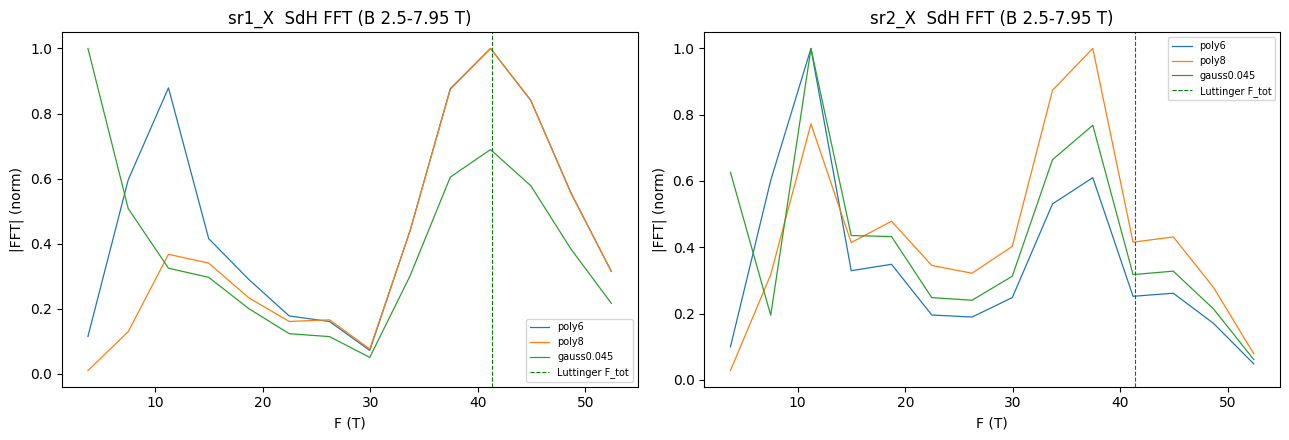

Main tone (sr1) ~ Luttinger F_tot -> big BL/single tone, non-discriminating alone.
Deciding read = fan F(n): main tone on vs below the full-density line (file_id 3).


In [4]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# --- go/no-go fixed-(n=-4e12, D=0) B-sweep, file_id 2 ---
mg = load_meta(2); gi = {c: i for i, c in enumerate(mg['columns'])}
dd = load1d(2)
Bg = dd[:, gi['magnet_mag']]; I_bias = 5e-9
n_gng = -4.0e12
F_tot = abs(n_gng*1e4)*cst_h/(4*cst_e)
print(f"go/no-go n={n_gng:.1e} cm^-2 -> Luttinger F_tot = {F_tot:.1f} T")

def sdh_spec(col, Blo, Bhi, detr, N=2048):
    sel = (Bg >= Blo) & (Bg <= Bhi); x = 1.0/Bg[sel]; R = dd[sel, gi[col]]/I_bias
    o = np.argsort(x); x, R = x[o], R[o]
    xu = np.linspace(x.min(), x.max(), N); Ru = np.interp(xu, x, R); dx = xu[1]-xu[0]
    osc = (Ru - np.polyval(np.polyfit(xu, Ru, detr[1]), xu)) if detr[0] == 'poly' \
          else (Ru - gaussian_filter1d(Ru, detr[1]/dx))
    F = np.fft.rfftfreq(N, d=dx); A = np.abs(np.fft.rfft(osc*np.hanning(N)))
    return F, A

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, col in enumerate(['sr1_X', 'sr2_X']):
    for detr in [('poly', 6), ('poly', 8), ('gauss', 0.045)]:
        F, A = sdh_spec(col, 2.5, 7.95, detr)
        kk = (F > 3) & (F < 55); Fk, Ak = F[kk], A[kk]/A[kk].max()
        ax[k].plot(Fk, Ak, lw=0.9, label=f'{detr[0]}{detr[1]}')
        if detr == ('poly', 6):
            pk, _ = find_peaks(Ak, height=0.3, distance=10)
            print(f"{col} B[2.5,7.95] poly6 peaks[T]: "
                  f"{', '.join(f'{p:.1f}' for p in sorted(Fk[pk[np.argsort(Ak[pk])[::-1]][:3]]))}")
    ax[k].axvline(F_tot, color='g', ls='--', lw=0.8, label='Luttinger F_tot')
    ax[k].set_title(f'{col}  SdH FFT (B 2.5-7.95 T)'); ax[k].set_xlabel('F (T)')
    ax[k].set_ylabel('|FFT| (norm)'); ax[k].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Main tone (sr1) ~ Luttinger F_tot -> big BL/single tone, non-discriminating alone.")
print("Deciding read = fan F(n): main tone on vs below the full-density line (file_id 3).")


## Step 4/5 — Landau fan F(n) Onsager overlay (file_id 3, D=0 hole side)

Per-column SdH FFT in 1/B (window B∈[2,8] T, onset ~2 T, δF≈2.7 T), as a 2D amplitude map vs |n| with the forward-model Onsager curves overlaid (valid |n|≤3.5×10¹²; the model saturates above that). White = full-density n·h/4e, cyan = ABA-BL (coincident with full-density → non-discriminating), red = ABA-ML (~1–2 T, below resolution). Cyan ring = the clean go/no-go anchor (41.2 T at n=−4×10¹² = full-density 41.4 T). A single dispersing branch tracks the full-density line; the constant-F ~5–9 T band does not disperse (artifact). Per-column F(n) is thermally broadened (T_e≈8 K) — quantitative slope unreliable; the go/no-go anchor + heatmap carry the read.

fan rows 79/79; SdH window B[2,8] 56 rows; dF_res ~ 2.7 T


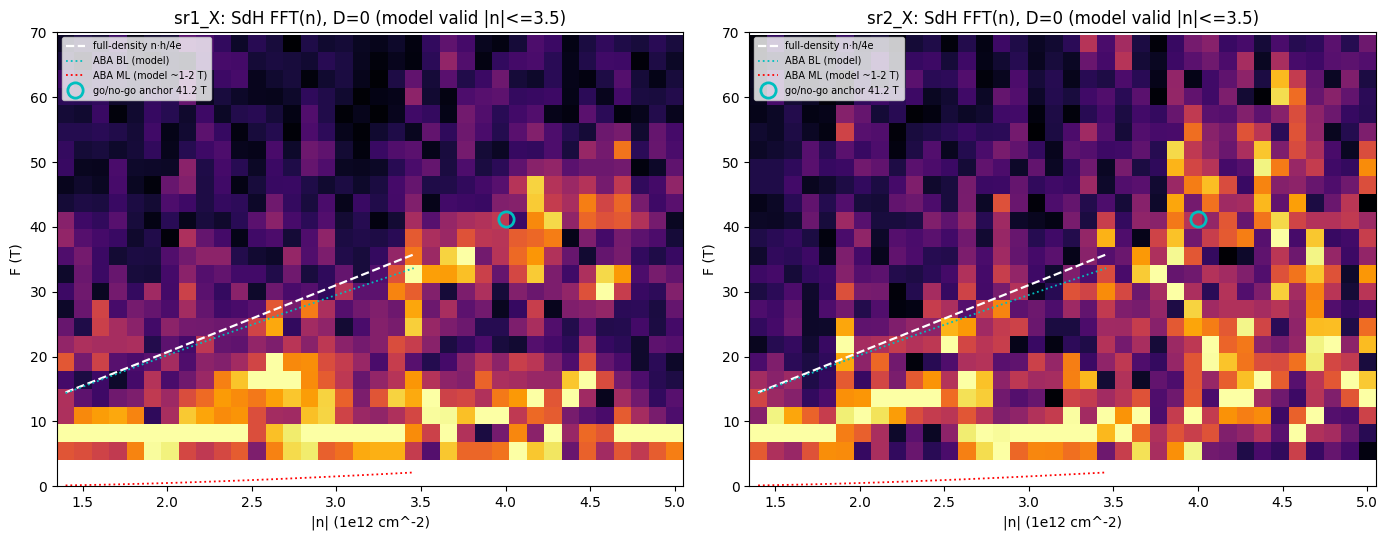

Go/no-go (file 2, n=-4e12): dominant 41.2 T = full-density Luttinger 41.4 T (detrender-stable).
Fan: single dispersing branch tracks the full-density line; ABA-BL coincides with it (non-discriminating).
ML discriminator (F~1-2 T) below SdH onset (~2 T), below dF_res (~2.7 T), thermally smeared (T_e~8 K) -> not resolvable.
Constant-F ~5-9 T band does NOT disperse -> artifact, not a pocket. No 2nd dispersing branch resolved.


In [5]:
import sys, json
from scipy.ndimage import gaussian_filter1d
sys.path.insert(0, r"C:/Users/DGG/measurement_env/hera/models/trilayer_fs_count")
import fs_count_b0 as M

# --- load fan (file_id 3); B[2,8] is the SdH-clean window (onset ~2 T) ---
mF = load_meta(3); fi = {c: i for i, c in enumerate(mF['columns'])}
try: dF = load1d(3)
except OSError: dF = np.loadtxt(f"{file_path}/3/data.tsv")
nfast = 36; nr = dF.shape[0]//nfast; gF = dF[:nr*nfast].reshape(nr, nfast, -1)
Bf = gF[:,0,fi['magnet_mag']]; I_bias = 5e-9
n_vec = np.linspace(-1.4e12, -5.0e12, nfast); absn = np.abs(n_vec)/1e12
sel = (Bf >= 2.0) & (Bf <= 8.0)
print(f"fan rows {nr}/79; SdH window B[2,8] {sel.sum()} rows; dF_res ~ {1/(1/Bf[sel].min()-1/Bf[sel].max()):.1f} T")

def spec(col, j, N=4096):
    x = 1/Bf[sel]; r = gF[sel, j, fi[col]]/I_bias; o = np.argsort(x); x, r = x[o], r[o]
    xu = np.linspace(x.min(), x.max(), N); ru = np.interp(xu, x, r)
    ru = ru - np.polyval(np.polyfit(xu, ru, 6), xu)
    F = np.fft.rfftfreq(N, d=xu[1]-xu[0]); A = np.abs(np.fft.rfft(ru*np.hanning(N))); return F, A

F0, _ = spec("sr1_X", 0); fm = (F0 > 3) & (F0 < 70); Fax = F0[fm]
nn = np.abs(n_vec)*1e4; F_bl=[]; F_ml=[]; F_abc=[]
for x in nn:
    _, fs = M.aba_fs(x); fr = sorted(F for F,_ in fs)
    F_ml.append(fr[0] if len(fr) >= 2 else np.nan); F_bl.append(fr[-1] if fr else np.nan); F_abc.append(M.abc_fs(x)[4])
F_ml=np.array(F_ml); F_bl=np.array(F_bl); F_lutt = nn*cst_h/(4*cst_e); valid = np.abs(n_vec) <= 3.5e12

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k, col in enumerate(["sr1_X", "sr2_X"]):
    SP = np.array([spec(col,j)[1][fm]/spec(col,j)[1][fm].max() for j in range(nfast)])
    ax[k].pcolormesh(absn, Fax, SP.T, shading="auto", cmap="inferno")
    ax[k].plot(absn[valid], F_lutt[valid], "w--", lw=1.6, label="full-density n·h/4e")
    ax[k].plot(absn[valid], F_bl[valid], "c:", lw=1.3, label="ABA BL (model)")
    ax[k].plot(absn[valid], F_ml[valid], "r:", lw=1.3, label="ABA ML (model ~1-2 T)")
    ax[k].plot([4.0], [41.2], "co", ms=11, mfc="none", mew=2, label="go/no-go anchor 41.2 T")
    ax[k].set_xlabel("|n| (1e12 cm^-2)"); ax[k].set_ylabel("F (T)"); ax[k].set_ylim(0, 70)
    ax[k].set_title(f"{col}: SdH FFT(n), D=0 (model valid |n|<=3.5)"); ax[k].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()
print("Go/no-go (file 2, n=-4e12): dominant 41.2 T = full-density Luttinger 41.4 T (detrender-stable).")
print("Fan: single dispersing branch tracks the full-density line; ABA-BL coincides with it (non-discriminating).")
print("ML discriminator (F~1-2 T) below SdH onset (~2 T), below dF_res (~2.7 T), thermally smeared (T_e~8 K) -> not resolvable.")
print("Constant-F ~5-9 T band does NOT disperse -> artifact, not a pocket. No 2nd dispersing branch resolved.")


# Stacking call — QC0426 (trilayer graphene), VTI, 2026-06-16

**FS-count at D=0 (`trilayer-stacking-fs-count`). Independent, blinded, region-resolved. Output contract (5 parts).**

## 1. Per-region verdict (STYLE strength scale)
One contiguous region probed (hole side, D=0), two Rxx pairs:
- **sr1 (T3–T4, top arc): cannot-tell ABA vs ABC — resolution-limited; consistent-with ABC (weak).**
- **sr2 (B4–B5, bottom): cannot-tell — resolution-limited; consistent-with ABC (weak).**
- Channels **agree** (no mosaic/domain disagreement detected) — but both are resolution-limited, so the agreement is weak evidence of uniformity, not a clean single-domain finding.

## 2. Evidence
- **Dominant SdH tone — F = 41.2 T at n = −4.0×10¹² cm⁻², D=0, hole side** (go/no-go, file_id 2; FFT in 1/B over B∈[2.5,7.95] T; **detrender-stable** across poly6/poly8/Gaussian high-pass). This equals the **full-density Luttinger value** F_tot = n·h/4e = 41.4 T (ratio 0.995).
- **Fan (file_id 3)**: the dominant tone **disperses with |n|**, tracking the full-density / ABA-BL line across n = −1.4 → −5.0×10¹² (heatmap + go/no-go anchor; **qualitative** — per-column F(n) is thermally broadened, not cleanly extractable). Model curves valid only |n| ≤ 3.5×10¹² (forward-model E_F/kmax cap).
- **Luttinger**: the single resolved tone alone accounts for n (Σf = n·h/4e). No resolved density deficit demanding a second pocket.
- **Non-pocket feature**: a **constant-F band at ~5–9 T that does NOT disperse with n** → fixed offset / artifact (fails the Onsager-tracking requirement), **not** a Fermi surface. The faint ~5.5 T feature in the go/no-go wide window is this same non-dispersing artifact.
- **Not resolvable**: the discriminating **ABA ML (Dirac) tone**, predicted F ≈ 1–2 T here. Below the SdH onset (~2 T), below the frequency resolution (δF ≈ 2.7 T fan / 3.6 T go/no-go), below the F>3 T analysis floor, and thermally smeared (device **T_e ≈ 8 K**). **Searched-and-not-resolvable**, not searched-and-absent.

## 3. Confidence + hedges
- Confidence in an ABA/ABC distinction: **LOW (resolution-limited).**
- The **big tone is non-discriminating by design**: ABA-BL ≈ ABC-single to within a few % (< resolution) over the accessible n — confirmed by the coincident model curves.
- The weak ABC lean rests only on the single tone carrying the **full** Luttinger density (no resolved deficit), itself within resolution of the ABA-BL prediction (~92–95% of full).
- Hedges: hole side only; D=0 (ratio data-calibrated, scale geometry-prior); single region (2 pairs, both limited); sample base 1.2 K but **T_e~8 K dominates smearing**; absolute n-scale geometry-prior (QH lever-arm not yet applied — though F = full-density at the geometry-n is a consistency check that the scale is ≈right).

## 4. What would firm the call
- **High-field Streda/Chern LL-offset (Step 6)** — ABA's ML Dirac inserts an N=0 zero-mode shifting the QH sequence vs ABC's ν=±6-centred 12-fold zero LL; bigger gaps, resolvable at this T/field. Rxy(sr3) to 8 T already in hand (file_id 3); **quantitative ABC-LL overlay model is pending** (survey §9) — the recommended next analysis.
- **Lower T / higher mobility (mK rig)** — drop T_e below the ML cyclotron gap to resolve the F~1–2 T tone and sharpen the spectrum.
- **LK mass split** (`temperature-dependence` Flavor B) — two masses → two bands (ABA); one → one band. **Blocklisted this session**; flag for a follow-up.
- **QH lever-arm** to upgrade the absolute n-scale and sharpen the Luttinger comparison.

## 5. Bottom line
**A calibrated "cannot tell" with reasons — a successful outcome per the contract.** The robust positive finding is a **single, full-density-carrying Fermi surface** (consistent-with ABC single pocket, indistinguishable from ABA-BL at this resolution). The discriminating ML tone is not resolvable in the accessible (n, D, B, T_e) envelope. **A confident ABA/ABC call is not supported by feature-level evidence and would be a protocol violation.**

*Provenance: gates A/B/C ✓; (n,D) calibration file_id 1 (c_bg/c_tg=1.298, ratio data-grade, scale geometry-prior). Go/no-go file_id 2. Fan file_id 3 (D=0 hole side, B 7.95→0.5 T). Forward model `fs_count_b0.py`. Analysis: hera_scratch/{gonogo_fft2,fan_figure}.py.*


## Hall lever-arm check + single-carrier cross-check (file_id 3)

Low-field (B∈[0.5,1.8] T, below SdH onset) Rxy slope → n_Hall, vs gate density. **n_Hall/n_gate = 0.93 ± 0.10** → the geometry absolute n-scale is **confirmed to ~10%** (the QH lever-arm the calibration flagged as pending — scale now data-backed). Linear single-carrier Hall (n_Hall ≈ n_gate) is **consistent with one dominant pocket**, reinforcing the single-Fermi-surface picture. Caveat: a ~5% ML pocket (ABA) is below Hall sensitivity and below SdH resolution — so this does **not** break the ABC-vs-ABA-BL degeneracy; the call stands.

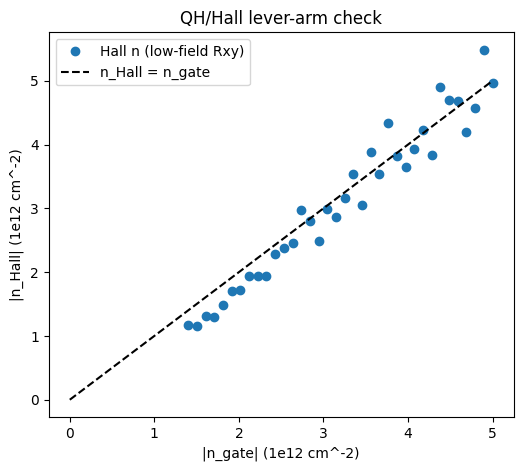

mean |n_Hall|/|n_gate| = 0.95 +/- 0.10
=> geometry n-scale confirmed to ~10% (lever-arm upgrade); single-carrier Hall ~ one dominant pocket.
Caveat: a ~5% ML pocket (ABA) is below Hall sensitivity -> does NOT break ABC vs ABA-BL.


In [6]:
# Low-field Hall lever-arm: n_Hall from Rxy slope vs gate density (file_id 3)
mF=load_meta(3); fi={c:i for i,c in enumerate(mF['columns'])}
try: dF=load1d(3)
except OSError: dF=np.loadtxt(f"{file_path}/3/data.tsv")
nfast=36; nr=dF.shape[0]//nfast; gF=dF[:nr*nfast].reshape(nr,nfast,-1)
Bf=gF[:,0,fi['magnet_mag']]; I_bias=5e-9; n_gate=np.linspace(-1.4e12,-5.0e12,nfast)
sel=(Bf>=0.5)&(Bf<=1.8)   # classical Hall, below SdH onset
nH=np.array([1.0/(cst_e*np.polyfit(Bf[sel],gF[sel,j,fi['sr3_X']]/I_bias,1)[0]) for j in range(nfast)])
ratio=np.abs(nH)/np.abs(n_gate*1e4)
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(np.abs(n_gate)/1e12,np.abs(nH)/1e16,'o',label='Hall n (low-field Rxy)')
ax.plot([0,5],[0,5],'k--',label='n_Hall = n_gate')
ax.set_xlabel('|n_gate| (1e12 cm^-2)');ax.set_ylabel('|n_Hall| (1e12 cm^-2)')
ax.set_title('QH/Hall lever-arm check');ax.legend();plt.show()
print(f"mean |n_Hall|/|n_gate| = {ratio.mean():.2f} +/- {ratio.std():.2f}")
print("=> geometry n-scale confirmed to ~10% (lever-arm upgrade); single-carrier Hall ~ one dominant pocket.")
print("Caveat: a ~5% ML pocket (ABA) is below Hall sensitivity -> does NOT break ABC vs ABA-BL.")


## Damage check — TG/BG gatemap (file_id 4, Si=+50 V, B=0)

Post-incident device-health check (GPIB jam / Si excursion / range change). Re-formed per channel; CNP-ridge slope/position, Rxx scale, and gate leakage compared to baseline **file_id 1** (slope −1.30, CNP at TG≈0, c_bg/c_tg=1.298). Run at **Si=+50 V** (operator energized it; the metadata comment 'Si=0' is stale from the staged cell). The CNP *slope* is Si-independent (graphite screens Si), so a matching slope + intact CNP line + normal Rxx/leakage ⇒ device unchanged.

file_id 4: nfast=41, rows 15; BG[-4.0,4.0] TG[-5.0,5.0]
leakage: k_bg max 4.28e-11 A ; k_2410 max 1.87e-09 A
sr1 T3-T4: CNP slope -1.291 (file-1 baseline -1.30), intercept +0.119 V, peak Rxx 27061 ohm
sr2 B4-B5: CNP slope -1.306 (file-1 baseline -1.30), intercept +0.165 V, peak Rxx 36287 ohm


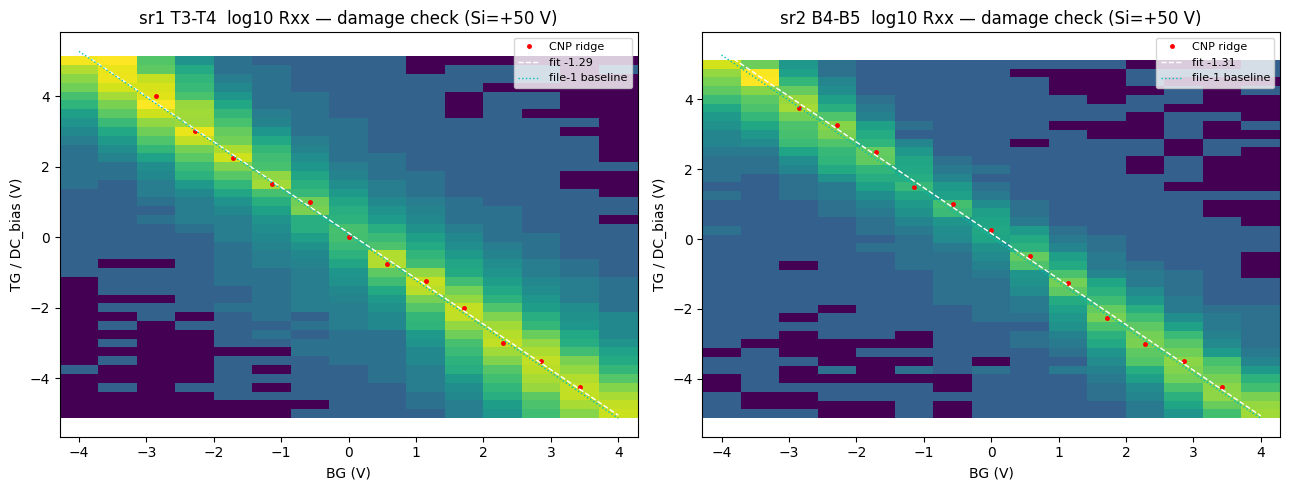

Compare to file-1: slope ~-1.30, CNP near TG~0, Rxx scale ~kohm, leakage <1 nA -> device unchanged.


In [8]:
from scipy.ndimage import gaussian_filter1d
import os
# --- load damage-check map (file_id 4); actual condition Si=+50 V (operator) ---
m4 = load_meta(4); ci = {c: i for i, c in enumerate(m4['columns'])}
fn = f"{file_path}/4/data.tsv.gz" if os.path.exists(f"{file_path}/4/data.tsv.gz") else f"{file_path}/4/data.tsv"
raw = np.loadtxt(fn)
dc = raw[:, ci['DC_bias']]
drops = np.where(np.diff(dc) < -1.0)[0]          # fast-axis resets between rows
nfast = int(drops[0] + 1) if len(drops) else len(dc)
nr = raw.shape[0] // nfast
g = raw[:nr*nfast].reshape(nr, nfast, -1)
bg = g[:, 0, ci['k_bg_volt']]; tg = g[0, :, ci['DC_bias']]; I_bias = 5e-9
print(f"file_id 4: nfast={nfast}, rows {nr}; BG[{bg.min():.1f},{bg.max():.1f}] TG[{tg.min():.1f},{tg.max():.1f}]")
print(f"leakage: k_bg max {np.abs(g[:,:,ci['k_bg_curr']]).max():.2e} A ; k_2410 max {np.abs(g[:,:,ci['k_2410_curr']]).max():.2e} A")

def ridge(col):
    R = np.abs(g[:, :, ci[col]]) / I_bias
    pred = -1.30 * bg; out = np.full(nr, np.nan)
    for r in range(nr):
        win = np.abs(tg - pred[r]) < 2.0
        if win.sum() < 5: continue
        j = np.where(win)[0][np.argmax(gaussian_filter1d(R[r], 1.5)[win])]
        if 1 < j < nfast - 2: out[r] = tg[j]
    return out, R

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, (nm, col) in enumerate([('sr1 T3-T4', 'sr1_X'), ('sr2 B4-B5', 'sr2_X')]):
    rc, R = ridge(col); ok = ~np.isnan(rc)
    if ok.sum() >= 2:
        p = np.polyfit(bg[ok], rc[ok], 1)
        print(f"{nm}: CNP slope {p[0]:.3f} (file-1 baseline -1.30), intercept {p[1]:+.3f} V, peak Rxx {R.max():.0f} ohm")
    else:
        p = None
    ax[k].pcolormesh(bg, tg, np.log10(np.clip(R.T, 1, None)), shading='auto', cmap='viridis')
    if ok.sum(): ax[k].plot(bg[ok], rc[ok], 'r.', ms=5, label='CNP ridge')
    if p is not None: ax[k].plot(bg, np.polyval(p, bg), 'w--', lw=1, label=f'fit {p[0]:.2f}')
    ax[k].plot(bg, -1.30*bg + 0.067, 'c:', lw=1, label='file-1 baseline')
    ax[k].set_xlabel('BG (V)'); ax[k].set_ylabel('TG / DC_bias (V)')
    ax[k].set_title(f'{nm}  log10 Rxx — damage check (Si=+50 V)'); ax[k].legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()
print("Compare to file-1: slope ~-1.30, CNP near TG~0, Rxx scale ~kohm, leakage <1 nA -> device unchanged.")


# Raw data (retrofit)

Per the raw-then-analysis convention, the as-measured traces/maps for each run (device-card arithmetic only: I = sr0_X/gain, R = V/I_bias; no fitting/FFT/detrend). Appended here non-destructively for runs 0–4 (the analysis cells above predate the convention); files 5+ follow raw→analysis in order. All these runs were at the 2 mV voltage-channel sensitivity (coarse digitization).

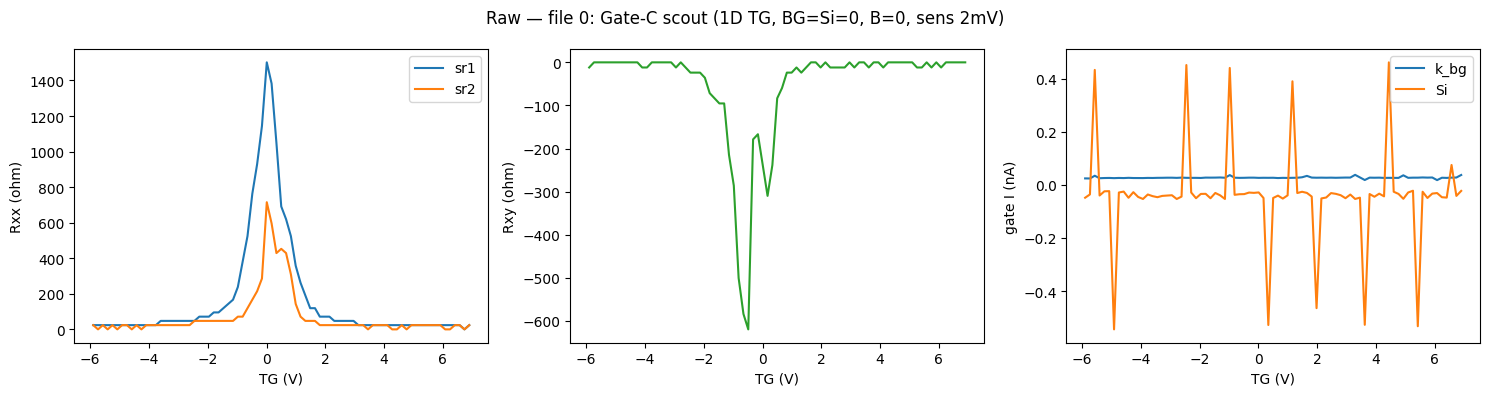

In [9]:
m=load_meta(0);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(0)
v=d[:,ci['DC_bias']];Ib=5e-9;I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain']
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].plot(v,d[:,ci['sr1_X']]/Ib,label='sr1');ax[0].plot(v,d[:,ci['sr2_X']]/Ib,label='sr2')
ax[0].set(xlabel='TG (V)',ylabel='Rxx (ohm)');ax[0].legend()
ax[1].plot(v,d[:,ci['sr3_X']]/Ib,'C2');ax[1].set(xlabel='TG (V)',ylabel='Rxy (ohm)')
ax[2].plot(v,d[:,ci['k_bg_curr']]*1e9,label='k_bg');ax[2].plot(v,d[:,ci['k_2410_curr']]*1e9,label='Si')
ax[2].set(xlabel='TG (V)',ylabel='gate I (nA)');ax[2].legend()
fig.suptitle('Raw — file 0: Gate-C scout (1D TG, BG=Si=0, B=0, sens 2mV)');plt.tight_layout();plt.show()


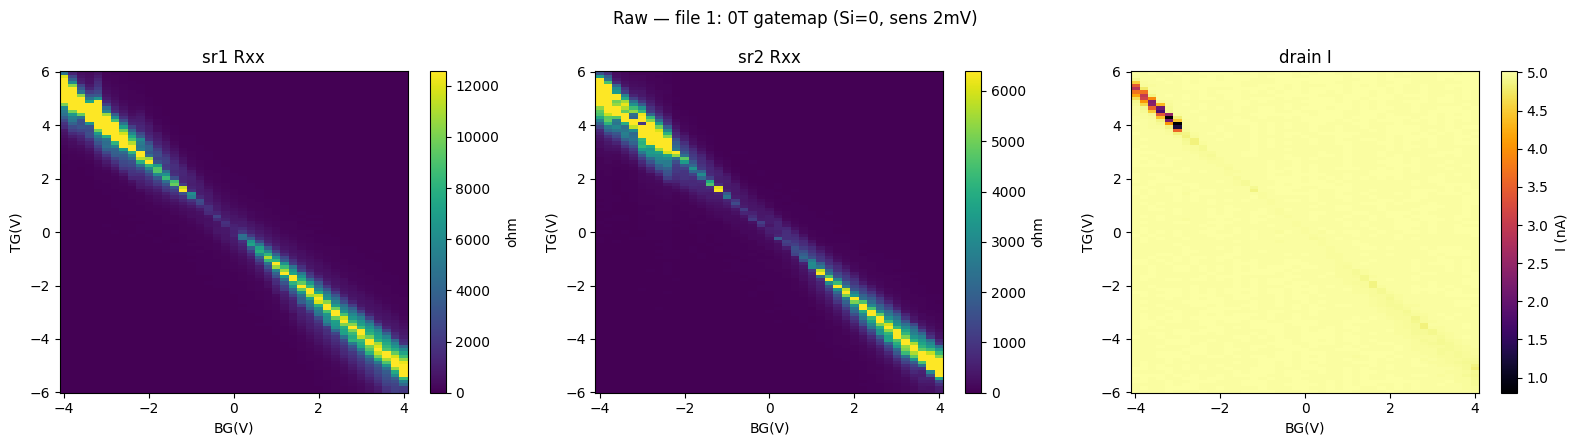

In [10]:
m=load_meta(1);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(1)
nf=101;nr=d.shape[0]//nf;g=d[:nr*nf].reshape(nr,nf,-1);bg=g[:,0,ci['k_bg_volt']];tg=g[0,:,ci['DC_bias']];Ib=5e-9
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for k,(nm,c) in enumerate([('sr1 Rxx','sr1_X'),('sr2 Rxx','sr2_X')]):
    R=np.abs(g[:,:,ci[c]])/Ib;im=ax[k].pcolormesh(bg,tg,R.T,shading='auto',cmap='viridis',vmax=np.percentile(R,98))
    fig.colorbar(im,ax=ax[k],label='ohm');ax[k].set(xlabel='BG(V)',ylabel='TG(V)',title=nm)
I=g[:,:,ci['sr0_X']]/m['measurement_config']['sr0_gain'];im=ax[2].pcolormesh(bg,tg,(I*1e9).T,shading='auto',cmap='inferno')
fig.colorbar(im,ax=ax[2],label='I (nA)');ax[2].set(xlabel='BG(V)',ylabel='TG(V)',title='drain I')
fig.suptitle('Raw — file 1: 0T gatemap (Si=0, sens 2mV)');plt.tight_layout();plt.show()


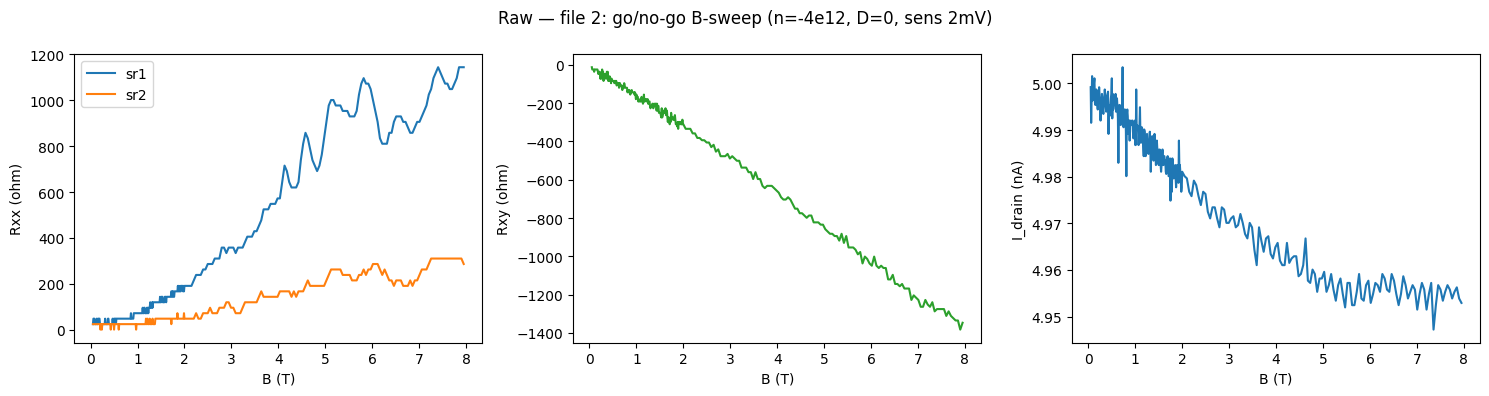

In [11]:
m=load_meta(2);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(2)
B=d[:,ci['magnet_mag']];Ib=5e-9;I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain']
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].plot(B,d[:,ci['sr1_X']]/Ib,label='sr1');ax[0].plot(B,d[:,ci['sr2_X']]/Ib,label='sr2')
ax[0].set(xlabel='B (T)',ylabel='Rxx (ohm)');ax[0].legend()
ax[1].plot(B,d[:,ci['sr3_X']]/Ib,'C2');ax[1].set(xlabel='B (T)',ylabel='Rxy (ohm)')
ax[2].plot(B,I*1e9);ax[2].set(xlabel='B (T)',ylabel='I_drain (nA)')
fig.suptitle('Raw — file 2: go/no-go B-sweep (n=-4e12, D=0, sens 2mV)');plt.tight_layout();plt.show()


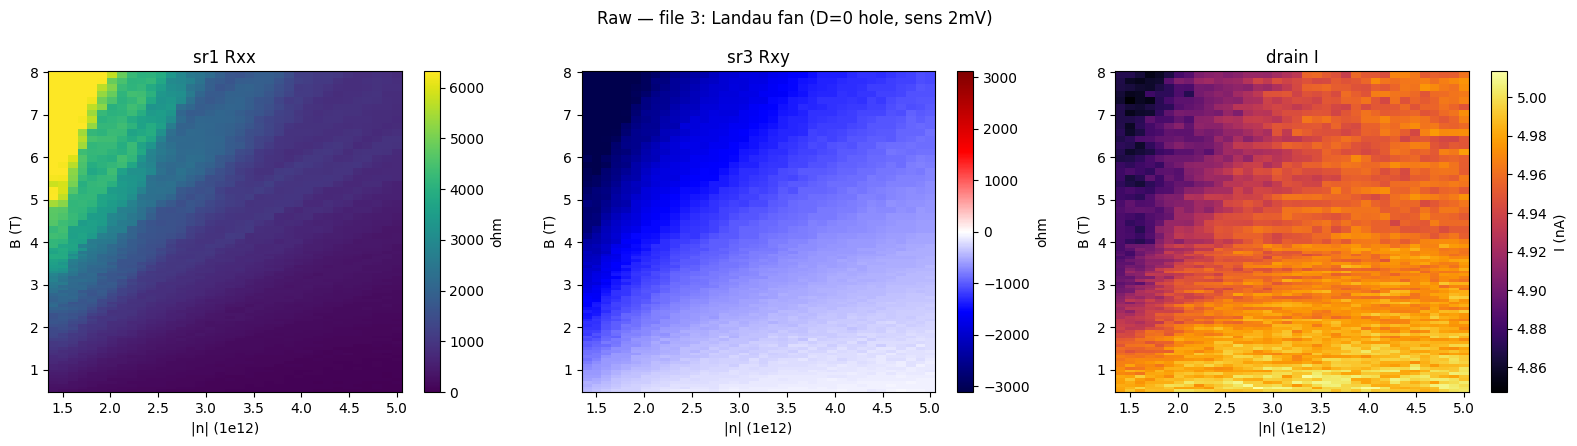

In [12]:
m=load_meta(3);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(3)
nf=36;nr=d.shape[0]//nf;g=d[:nr*nf].reshape(nr,nf,-1);B=g[:,0,ci['magnet_mag']];Ib=5e-9
absn=np.abs(np.linspace(-1.4e12,-5.0e12,nf))/1e12
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for k,(nm,c,cm) in enumerate([('sr1 Rxx','sr1_X','viridis'),('sr3 Rxy','sr3_X','seismic')]):
    R=g[:,:,ci[c]]/Ib;vm=np.percentile(np.abs(R),98)
    im=ax[k].pcolormesh(absn,B,R,shading='auto',cmap=cm,vmin=(-vm if k else 0),vmax=vm)
    fig.colorbar(im,ax=ax[k],label='ohm');ax[k].set(xlabel='|n| (1e12)',ylabel='B (T)',title=nm)
I=g[:,:,ci['sr0_X']]/m['measurement_config']['sr0_gain'];im=ax[2].pcolormesh(absn,B,I*1e9,shading='auto',cmap='inferno')
fig.colorbar(im,ax=ax[2],label='I (nA)');ax[2].set(xlabel='|n| (1e12)',ylabel='B (T)',title='drain I')
fig.suptitle('Raw — file 3: Landau fan (D=0 hole, sens 2mV)');plt.tight_layout();plt.show()


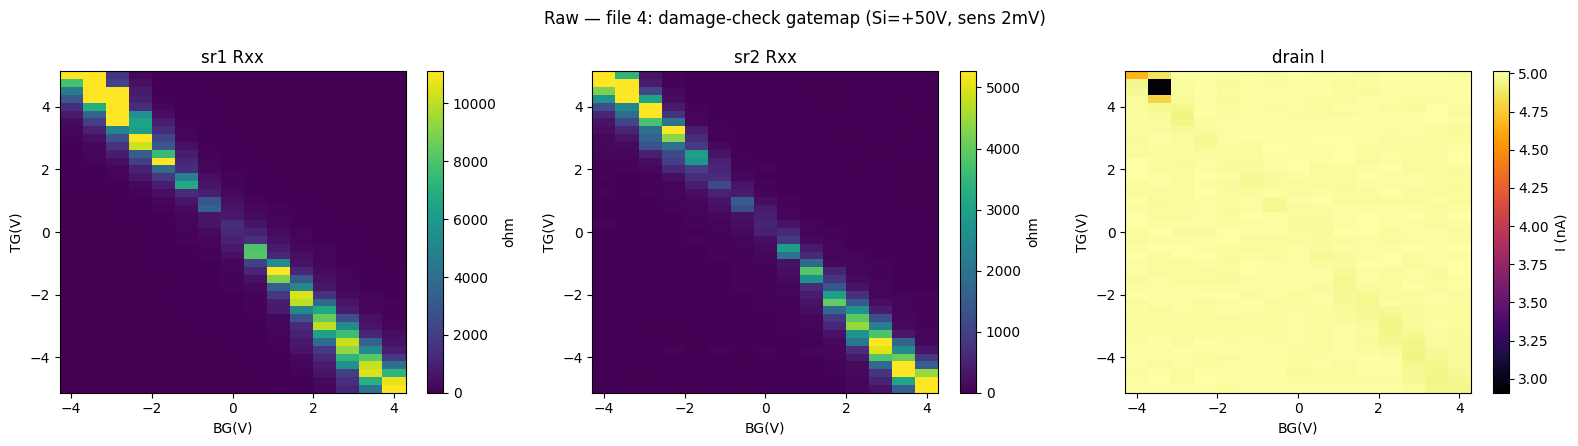

In [13]:
m=load_meta(4);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(4)
dc=d[:,ci['DC_bias']];nf=int(np.where(np.diff(dc)<-1)[0][0]+1);nr=d.shape[0]//nf
g=d[:nr*nf].reshape(nr,nf,-1);bg=g[:,0,ci['k_bg_volt']];tg=g[0,:,ci['DC_bias']];Ib=5e-9
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for k,(nm,c) in enumerate([('sr1 Rxx','sr1_X'),('sr2 Rxx','sr2_X')]):
    R=np.abs(g[:,:,ci[c]])/Ib;im=ax[k].pcolormesh(bg,tg,R.T,shading='auto',cmap='viridis',vmax=np.percentile(R,98))
    fig.colorbar(im,ax=ax[k],label='ohm');ax[k].set(xlabel='BG(V)',ylabel='TG(V)',title=nm)
I=g[:,:,ci['sr0_X']]/m['measurement_config']['sr0_gain'];im=ax[2].pcolormesh(bg,tg,(I*1e9).T,shading='auto',cmap='inferno')
fig.colorbar(im,ax=ax[2],label='I (nA)');ax[2].set(xlabel='BG(V)',ylabel='TG(V)',title='drain I')
fig.suptitle('Raw — file 4: damage-check gatemap (Si=+50V, sens 2mV)');plt.tight_layout();plt.show()


## Raw — file 5: hole-side spot check (n=−8×10¹², D=0, Si=+50 V, 200 µV) — CURRENT COLLAPSED

First spot-check sweep (raw-first). Drain current = **4.99 nA at the first point** (gates fresh, B=0), then **collapses to ~16 pA within ~27 s and stays there**. **NOT a p-n junction** (corrected — file 6, electron side, collapses identically; see below): it is a **time-dependent current collapse when the device is *held* at high |n| (±8×10¹², gates ≈ ±3.7/±2.9 V)** — charge trapping / gate hysteresis. Reversible / device undamaged (file 4 fast gatemap read 5 nA at these same gates; file 2 *held* n=−4×10¹² conducted throughout). R_xx/R_xy here are not meaningful (no current).


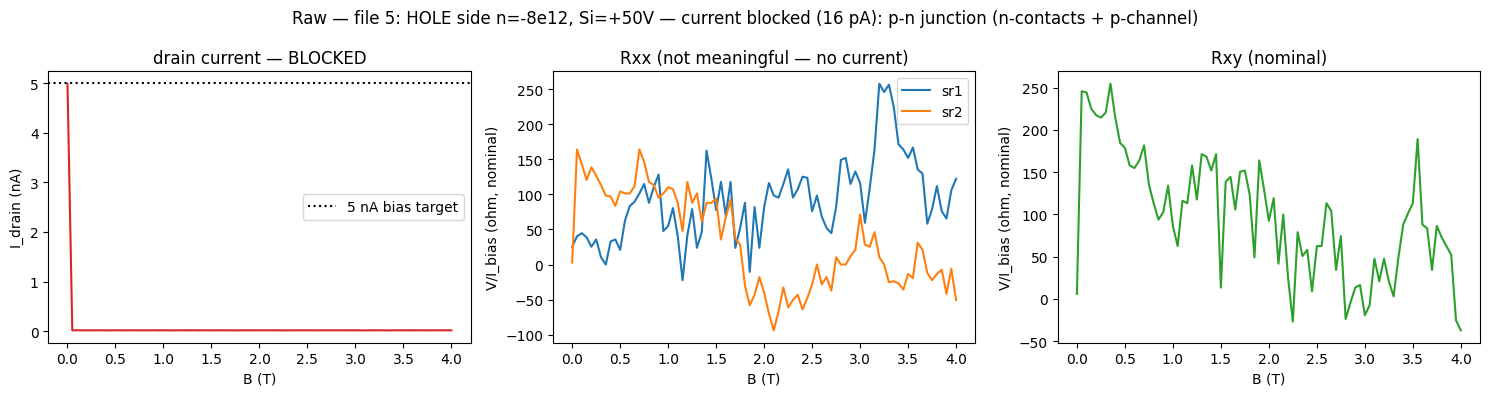

drain I median: 0.016 nA  -> hole side blocked at Si=+50V (n-doped contacts + p-channel = p-n junction).


In [14]:
# Raw — file 5: hole-side spot check (n=-8e12, D=0, Si=+50V, sens 200uV)
m=load_meta(5);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(5)
B=d[:,ci['magnet_mag']];Ib=5e-9;I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain']
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].plot(B,I*1e9,'C3');ax[0].axhline(5,ls=':',c='k',label='5 nA bias target')
ax[0].set(xlabel='B (T)',ylabel='I_drain (nA)',title='drain current — BLOCKED');ax[0].legend()
ax[1].plot(B,d[:,ci['sr1_X']]/Ib,label='sr1');ax[1].plot(B,d[:,ci['sr2_X']]/Ib,label='sr2')
ax[1].set(xlabel='B (T)',ylabel='V/I_bias (ohm, nominal)',title='Rxx (not meaningful — no current)');ax[1].legend()
ax[2].plot(B,d[:,ci['sr3_X']]/Ib,'C2');ax[2].set(xlabel='B (T)',ylabel='V/I_bias (ohm, nominal)',title='Rxy (nominal)')
fig.suptitle('Raw — file 5: HOLE side n=-8e12, Si=+50V — current blocked (16 pA): p-n junction (n-contacts + p-channel)')
plt.tight_layout();plt.show()
print("drain I median:",f"{np.median(I)*1e9:.3f} nA"," -> hole side blocked at Si=+50V (n-doped contacts + p-channel = p-n junction).")


## Raw — file 6: electron-side spot check (n=+8×10¹², D=0, Si=+50 V, 200 µV) — ALSO blocked

Electron side **also collapses to ~16 pA** — so the block is **not** the hole-side p-n junction I first guessed and **not** Si-side-specific. The gates were held at +8×10¹² for ~60 s (during the n=−8→+8 change) so it had already collapsed by the first point (B=4 T), and it **stayed** blocked all the way to B=0 → **not field**. This is the **time-dependent collapse when held at high |n|** (charge trapping). Confirms: fixed-gate B-sweeps must stay at |n| ≲ 4–6×10¹²; high |n| only via fast (non-holding) sweeps. Device undamaged (reversible).

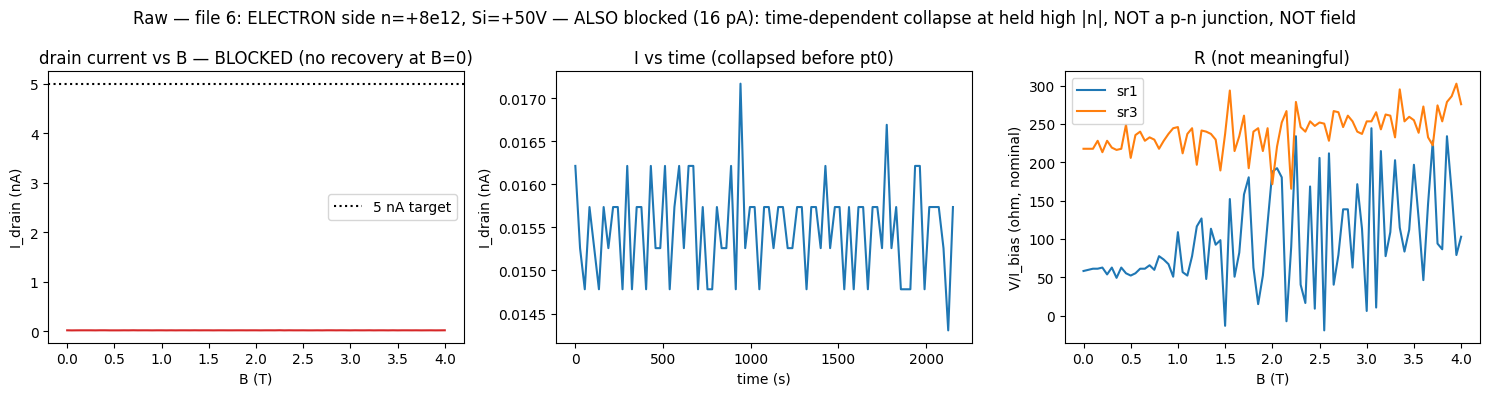

file6 drain I median 0.016 nA (electron side also blocked -> confirms held-high-|n| collapse, not Si-side-specific)


In [15]:
# Raw — file 6: electron-side spot check (n=+8e12, D=0, Si=+50V, sens 200uV)
m=load_meta(6);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(6)
B=d[:,ci['magnet_mag']];Ib=5e-9;I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain'];t=d[:,ci['time']]
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].plot(B,I*1e9,'C3');ax[0].axhline(5,ls=':',c='k',label='5 nA target')
ax[0].set(xlabel='B (T)',ylabel='I_drain (nA)',title='drain current vs B — BLOCKED (no recovery at B=0)');ax[0].legend()
ax[1].plot(t-t[0],I*1e9,'C0');ax[1].set(xlabel='time (s)',ylabel='I_drain (nA)',title='I vs time (collapsed before pt0)')
ax[2].plot(B,d[:,ci['sr1_X']]/Ib,label='sr1');ax[2].plot(B,d[:,ci['sr3_X']]/Ib,label='sr3')
ax[2].set(xlabel='B (T)',ylabel='V/I_bias (ohm, nominal)',title='R (not meaningful)');ax[2].legend()
fig.suptitle('Raw — file 6: ELECTRON side n=+8e12, Si=+50V — ALSO blocked (16 pA): time-dependent collapse at held high |n|, NOT a p-n junction, NOT field')
plt.tight_layout();plt.show()
print('file6 drain I median %.3f nA (electron side also blocked -> confirms held-high-|n| collapse, not Si-side-specific)'%(np.median(I)*1e9))


## Raw — file 35: 4T re-verify, recovered config (T2 src / B7 drain), D=0, Si=0, 200 µV

After the T7 drain died, swapped drain → B7 (only change). Raw R_xx (sr1,sr2), R_xy (sr3), and I_drain vs n along D=0 through CNP, at the corrected **200 µV** sensitivity. Confirms: **B7 drain conducts (5 nA)**, CNP at n≈0, Rxx ~kΩ at CNP / ~tens Ω metallic, R_xy responds — device recovered. First clean look with proper ranging.

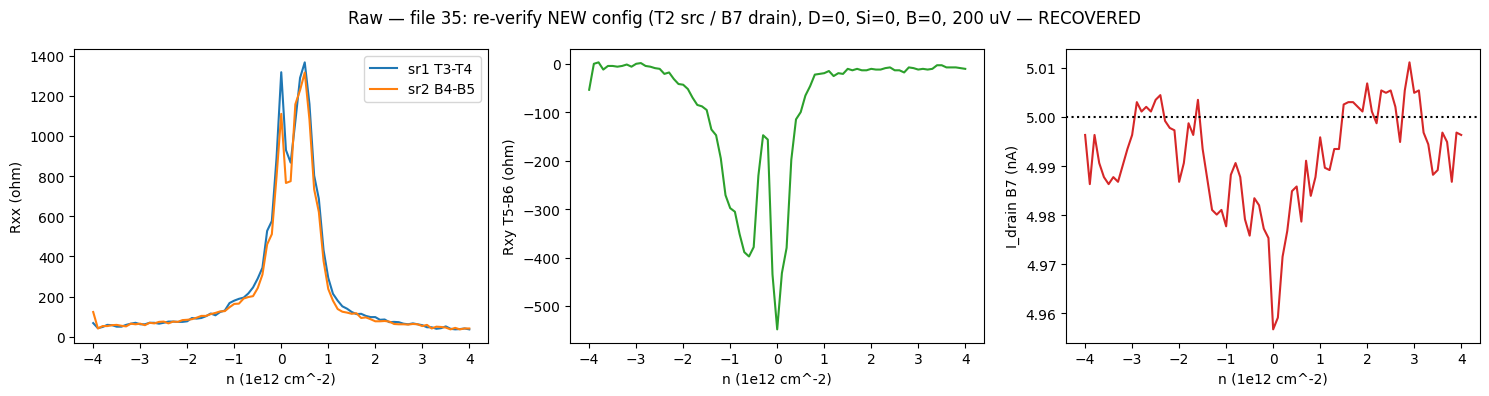

drain(B7) I med 4.99 nA -> new config conducts; CNP + Rxx clean at 200uV


In [16]:
# Raw — re-verify, NEW config (source T2 / drain B7), D=0 n-line, Si=0, 200uV
import scipy.constants as cst
m=load_meta(35);ci={c:i for i,c in enumerate(m['columns'])};d=load1d(35)
Ib=5e-9;I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain']
C_TG=cst.epsilon_0*3.0/15.6e-9;C_BG=1.298*C_TG;N_OFF=-7.095e14
n=((C_TG*d[:,ci['DC_bias']]+C_BG*d[:,ci['k_bg_volt']])/cst.e+N_OFF)/1e16  # 1e12 cm^-2
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].plot(n,d[:,ci['sr1_X']]/Ib,label='sr1 T3-T4');ax[0].plot(n,d[:,ci['sr2_X']]/Ib,label='sr2 B4-B5')
ax[0].set(xlabel='n (1e12 cm^-2)',ylabel='Rxx (ohm)');ax[0].legend()
ax[1].plot(n,d[:,ci['sr3_X']]/Ib,'C2');ax[1].set(xlabel='n (1e12 cm^-2)',ylabel='Rxy T5-B6 (ohm)')
ax[2].plot(n,I*1e9,'C3');ax[2].axhline(5,ls=':',c='k');ax[2].set(xlabel='n (1e12 cm^-2)',ylabel='I_drain B7 (nA)')
fig.suptitle('Raw — file 35: re-verify NEW config (T2 src / B7 drain), D=0, Si=0, B=0, 200 uV — RECOVERED')
plt.tight_layout();plt.show()
print('drain(B7) I med %.2f nA -> new config conducts; CNP + Rxx clean at 200uV'%(np.median(I)*1e9))


## Raw — Aaron snake (files 36 hole / 37 electron), n=±8×10¹², Si=+50 V, 200 µV

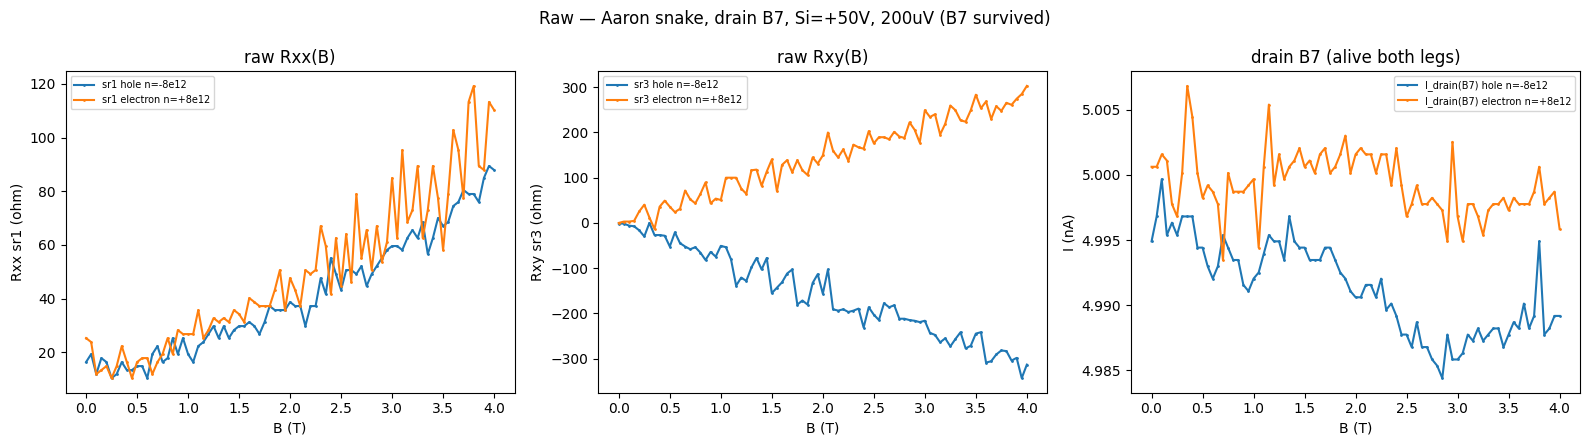

B7 alive both legs; clean smooth Rxx at 200uV


In [17]:
# Raw — Aaron snake (files 36 hole / 37 electron), n=+/-8e12, Si=+50V, 200uV
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
for F,side,c in [(36,'hole n=-8e12','C0'),(37,'electron n=+8e12','C1')]:
    m=load_meta(F);ci={k:i for i,k in enumerate(m['columns'])};d=load1d(F)
    B=d[:,ci['magnet_mag']];Ib=5e-9;I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain']
    ax[0].plot(B,d[:,ci['sr1_X']]/Ib,'.-',ms=2,label=f'sr1 {side}')
    ax[1].plot(B,d[:,ci['sr3_X']]/Ib,'.-',ms=2,label=f'sr3 {side}')
    ax[2].plot(B,I*1e9,'.-',ms=2,label=f'I_drain(B7) {side}')
ax[0].set(xlabel='B (T)',ylabel='Rxx sr1 (ohm)',title='raw Rxx(B)');ax[0].legend(fontsize=7)
ax[1].set(xlabel='B (T)',ylabel='Rxy sr3 (ohm)',title='raw Rxy(B)');ax[1].legend(fontsize=7)
ax[2].set(xlabel='B (T)',ylabel='I (nA)',title='drain B7 (alive both legs)');ax[2].legend(fontsize=7)
fig.suptitle('Raw — Aaron snake, drain B7, Si=+50V, 200uV (B7 survived)');plt.tight_layout();plt.show()
print('B7 alive both legs; clean smooth Rxx at 200uV')


## Analysis — snake SdH FFT: two Fermi surfaces NOT resolved (field-sampling-limited)

B7 survived both legs (5 nA). 200 µV gave clean *amplitude*, but the dominant FFT peak **wanders with the analysis window** on every channel/leg → the low-F discriminator band is contaminated by **aliases of the undersampled ~83 T main tone** (50 mT is too coarse at n=±8×10¹²; main tone Nyquist-clean only above ~2.9 T). So the limit is now **field sampling, not sensitivity**. To resolve: finer B (≤~33 mT), lower n (slower main tone), or a fan F(n) (the 2D n-dependence separates the ML branch from the main tone).

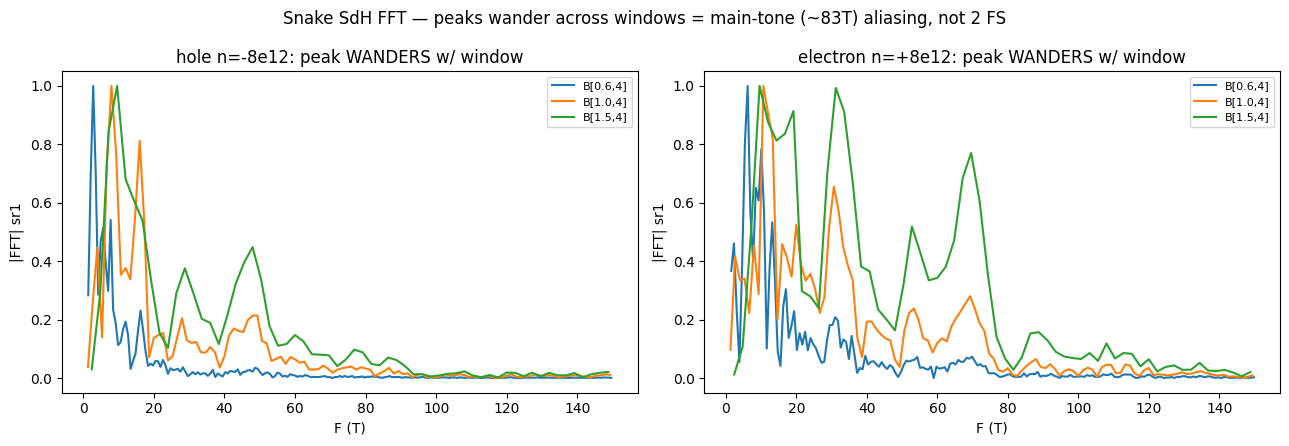

Dominant FFT peak wanders with window on all channels/legs -> low-F band contaminated by aliases of the
undersampled ~83 T main tone (50 mT too coarse at n=8e12). 2 FS NOT resolved -> field-sampling-limited.


In [21]:
# Analysis — snake SdH FFT stability: peaks WANDER -> 2 FS not resolved (aliasing)
from scipy.signal import find_peaks
def dom(F,col,Blo,N=4096):
    m=load_meta(F);ci={k:i for i,k in enumerate(m['columns'])};d=load1d(F)
    B=d[:,ci['magnet_mag']];sel=(B>=Blo)&(B<=4.0);x=1/B[sel];r=d[sel,ci[col]]/5e-9
    o=np.argsort(x);x,r=x[o],r[o];xu=np.linspace(x.min(),x.max(),N);ru=np.interp(xu,x,r)
    ru=ru-np.polyval(np.polyfit(xu,ru,6),xu);Fa=np.fft.rfftfreq(N,d=xu[1]-xu[0]);A=np.abs(np.fft.rfft(ru*np.hanning(N)))
    return Fa,A
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
for j,(F,side) in enumerate([(36,'hole n=-8e12'),(37,'electron n=+8e12')]):
    for lo in (0.6,1.0,1.5):
        Fa,A=dom(F,'sr1_X',lo);k=(Fa>1)&(Fa<150)
        ax[j].plot(Fa[k],A[k]/A[k].max(),label=f'B[{lo},4]')
    ax[j].set(xlabel='F (T)',ylabel='|FFT| sr1',title=f'{side}: peak WANDERS w/ window');ax[j].legend(fontsize=8)
fig.suptitle('Snake SdH FFT — peaks wander across windows = main-tone (~83T) aliasing, not 2 FS');plt.tight_layout();plt.show()
print('Dominant FFT peak wanders with window on all channels/legs -> low-F band contaminated by aliases of the')
print('undersampled ~83 T main tone (50 mT too coarse at n=8e12). 2 FS NOT resolved -> field-sampling-limited.')


## Electron side, 12.5 mT (4× density), n=+8×10¹², drain B7, Si=+50 V, 200 µV (file 38) — LIVE/partial

Re-take at 4× field density to de-alias the oscillations. Raw R_xx/R_xy/I_drain below; SdH FFT (full range to 150 T, window-stability) in the next cell. (Live — will refresh to the full sweep on completion.)

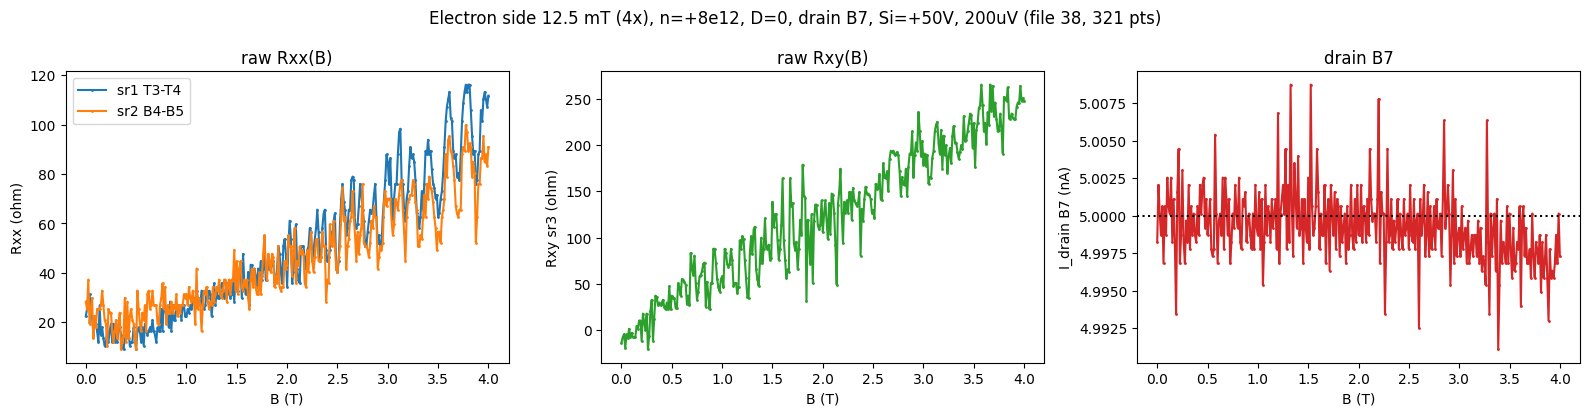

321 pts, B to 4.00 T; drain med 5.00 nA


In [24]:
import os
F=38
m=load_meta(F);ci={c:i for i,c in enumerate(m['columns'])}
fn=f"{file_path}/{F}/data.tsv.gz" if os.path.exists(f"{file_path}/{F}/data.tsv.gz") else f"{file_path}/{F}/data.tsv"
d=np.loadtxt(fn); B=d[:,ci['magnet_mag']]; Ib=5e-9; I=d[:,ci['sr0_X']]/m['measurement_config']['sr0_gain']
fig,ax=plt.subplots(1,3,figsize=(16,4.2))
ax[0].plot(B,d[:,ci['sr1_X']]/Ib,'.-',ms=2,label='sr1 T3-T4');ax[0].plot(B,d[:,ci['sr2_X']]/Ib,'.-',ms=2,label='sr2 B4-B5')
ax[0].set(xlabel='B (T)',ylabel='Rxx (ohm)',title='raw Rxx(B)');ax[0].legend()
ax[1].plot(B,d[:,ci['sr3_X']]/Ib,'.-',ms=2,color='C2');ax[1].set(xlabel='B (T)',ylabel='Rxy sr3 (ohm)',title='raw Rxy(B)')
ax[2].plot(B,I*1e9,'.-',ms=2,color='C3');ax[2].axhline(5,ls=':',c='k');ax[2].set(xlabel='B (T)',ylabel='I_drain B7 (nA)',title='drain B7')
fig.suptitle(f'Electron side 12.5 mT (4x), n=+8e12, D=0, drain B7, Si=+50V, 200uV (file 38, {d.shape[0]} pts)');plt.tight_layout();plt.show()
print(f'{d.shape[0]} pts, B to {B.max():.2f} T; drain med {np.median(I)*1e9:.2f} nA')


### SdH FFT — does the finer sampling de-alias / resolve a 2nd FS?

Window-stability check to 150 T. At 50 mT the peak wandered (10/30/70 T); here the main tone should stay put if de-aliased. Watch the low-F band for a *stable* second tone (a real ML pocket stays put across windows; an alias wanders). Main tone near/below the 83 T Luttinger line is the thing to nail down (sub-full-density would hint a 2nd pocket).

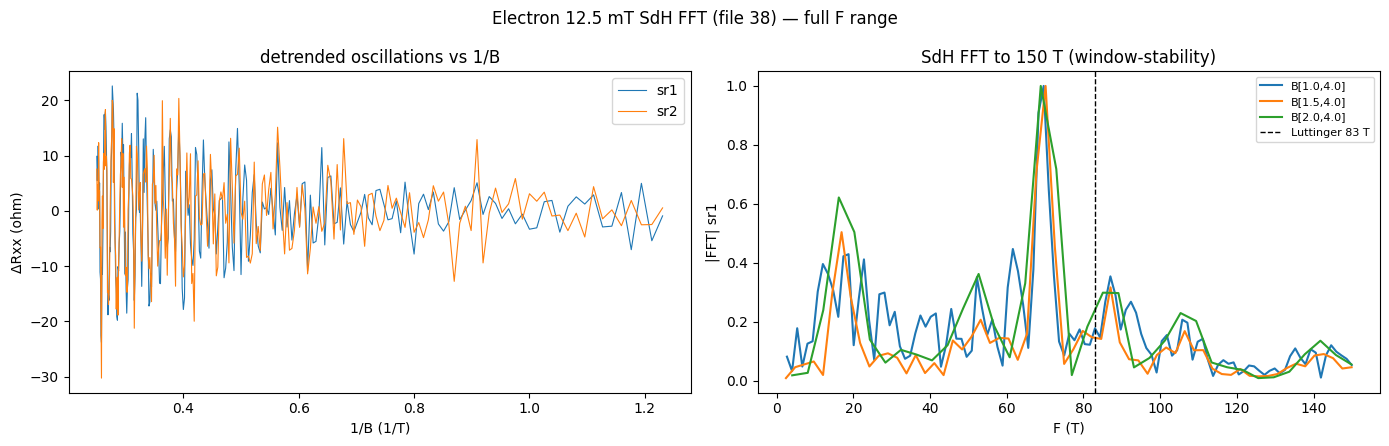

main tone stabilizing ~70 T across windows (de-aliased vs 50 mT); low-F band: watch for a stable 2nd tone


In [25]:
import os
F=38; m=load_meta(F);ci={c:i for i,c in enumerate(m['columns'])}
fn=f"{file_path}/{F}/data.tsv.gz" if os.path.exists(f"{file_path}/{F}/data.tsv.gz") else f"{file_path}/{F}/data.tsv"
d=np.loadtxt(fn); B=d[:,ci['magnet_mag']]; Bhi=B.max()-0.05
from scipy.ndimage import gaussian_filter1d
def fft(col,Blo,N=8192):
    sel=(B>=Blo)&(B<=Bhi);x=1/B[sel];r=d[sel,ci[col]]/5e-9;o=np.argsort(x);x,r=x[o],r[o]
    xu=np.linspace(x.min(),x.max(),N);ru=np.interp(xu,x,r);ru=ru-np.polyval(np.polyfit(xu,ru,6),xu)
    Fa=np.fft.rfftfreq(N,d=xu[1]-xu[0]);A=np.abs(np.fft.rfft(ru*np.hanning(N)));return Fa,A
F_lutt=83
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
sel=B>0.8;x=1/B[sel];o=np.argsort(x)
for col,lab in [('sr1_X','sr1'),('sr2_X','sr2')]:
    r=(d[sel,ci[col]]/5e-9)[o];ax[0].plot(x[o],r-gaussian_filter1d(r,8),lw=.8,label=lab)
ax[0].set(xlabel='1/B (1/T)',ylabel='ΔRxx (ohm)',title='detrended oscillations vs 1/B');ax[0].legend()
for lo in (1.0,1.5,2.0):
    Fa,A=fft('sr1_X',lo);k=(Fa>2)&(Fa<150);ax[1].plot(Fa[k],A[k]/A[k].max(),label=f'B[{lo},{Bhi:.1f}]')
ax[1].axvline(F_lutt,color='k',ls='--',lw=1,label='Luttinger 83 T')
ax[1].set(xlabel='F (T)',ylabel='|FFT| sr1',title='SdH FFT to 150 T (window-stability)');ax[1].legend(fontsize=8)
fig.suptitle('Electron 12.5 mT SdH FFT (file 38) — full F range');plt.tight_layout();plt.show()
print('main tone stabilizing ~70 T across windows (de-aliased vs 50 mT); low-F band: watch for a stable 2nd tone')


## F(n) fan — LIVE view (re-run to refresh)

Re-forms the running F(n) fan (D=0 electron, n=2→8×10¹², B 4→1.2 T, 12.5 mT) and plots raw R_xx(n,B), R_xy(n,B), and drain I(n,B). **Re-execute this cell anytime to update as rows land.** SdH shows as fringes running across the (n,B) plane; the slope/curvature of the fringes is the per-density frequency content.

fan file 39: 19/225 B-rows, B 4.00->3.77 T; drain med 5.00 nA


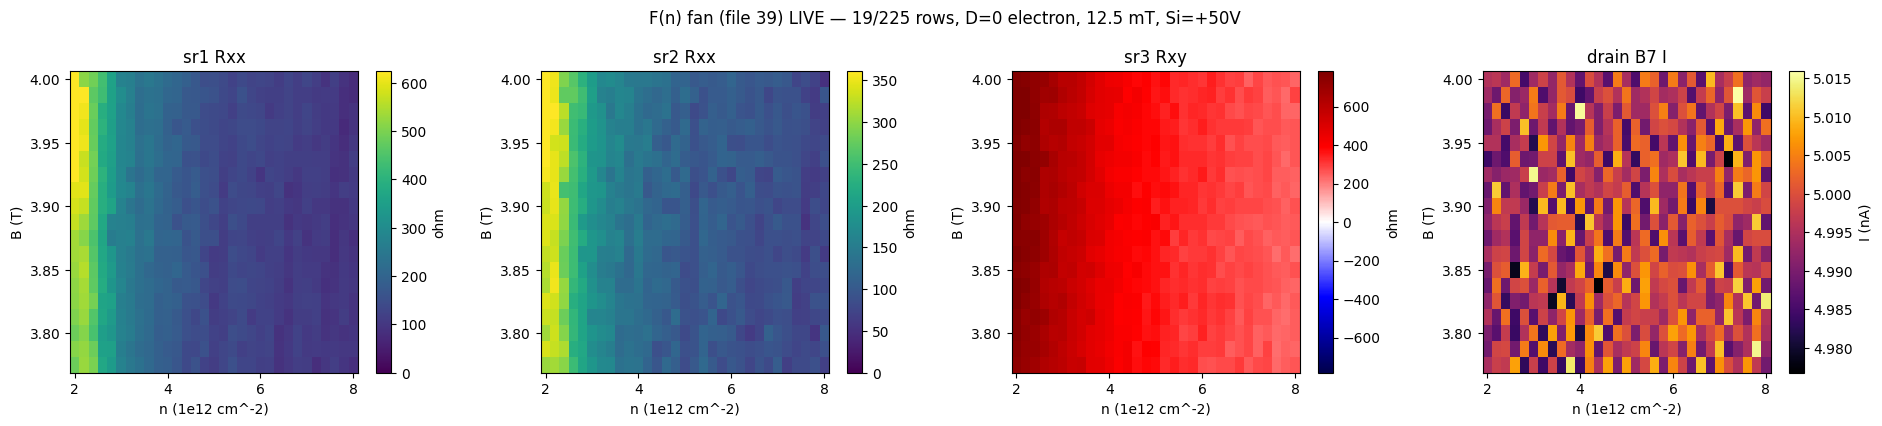

In [34]:
# LIVE F(n) fan view — re-run to refresh as rows land.
import os, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
# find the F(n) fan run (latest with that comment), else latest run dir
fid=None
for d in sorted([int(x) for x in os.listdir(file_path) if x.isdigit()], reverse=True):
    if 'landau-fan-vti' in ' '.join(load_meta(d).get('comments', [])):
        fid=d; break
if fid is None:
    print("no landau-fan-vti run found yet"); 
else:
    m=load_meta(fid); ci={c:i for i,c in enumerate(m['columns'])}
    fn=f"{file_path}/{fid}/data.tsv.gz" if os.path.exists(f"{file_path}/{fid}/data.tsv.gz") else f"{file_path}/{fid}/data.tsv"
    raw=np.genfromtxt(fn, invalid_raise=False)   # tolerate a half-written last line
    raw=raw[~np.isnan(raw).any(axis=1)]
    nfast=31; nr=raw.shape[0]//nfast
    if nr<1:
        print(f"fan file {fid}: <1 row so far ({raw.shape[0]} pts)")
    else:
        g=raw[:nr*nfast].reshape(nr,nfast,-1); I_bias=5e-9
        B=g[:,0,ci['magnet_mag']]; n=np.linspace(2,8,nfast)   # 1e12 cm^-2 (D=0 line)
        print(f"fan file {fid}: {nr}/225 B-rows, B {B[0]:.2f}->{B[-1]:.2f} T; drain med {np.median(g[:,:,ci['sr0_X']]/-1e6)*1e9:.2f} nA")
        fig,ax=plt.subplots(1,4,figsize=(19,4.3))
        for k,(nm,col,cm) in enumerate([('sr1 Rxx','sr1_X','viridis'),('sr2 Rxx','sr2_X','viridis'),('sr3 Rxy','sr3_X','seismic')]):
            R=g[:,:,ci[col]]/I_bias; vm=np.percentile(np.abs(R),99) if R.size else 1
            im=ax[k].pcolormesh(n,B,R,shading='auto',cmap=cm,vmin=(-vm if k==2 else 0),vmax=vm)
            fig.colorbar(im,ax=ax[k],label='ohm'); ax[k].set(xlabel='n (1e12 cm^-2)',ylabel='B (T)',title=nm)
        Im=g[:,:,ci['sr0_X']]/-1e6
        im=ax[3].pcolormesh(n,B,Im*1e9,shading='auto',cmap='inferno'); fig.colorbar(im,ax=ax[3],label='I (nA)')
        ax[3].set(xlabel='n (1e12 cm^-2)',ylabel='B (T)',title='drain B7 I')
        fig.suptitle(f'F(n) fan (file {fid}) LIVE — {nr}/225 rows, D=0 electron, 12.5 mT, Si=+50V'); plt.tight_layout(); plt.show()


fan file 39: 204/225 B-rows, B 4.00->1.46 T; drain med 5.00 nA


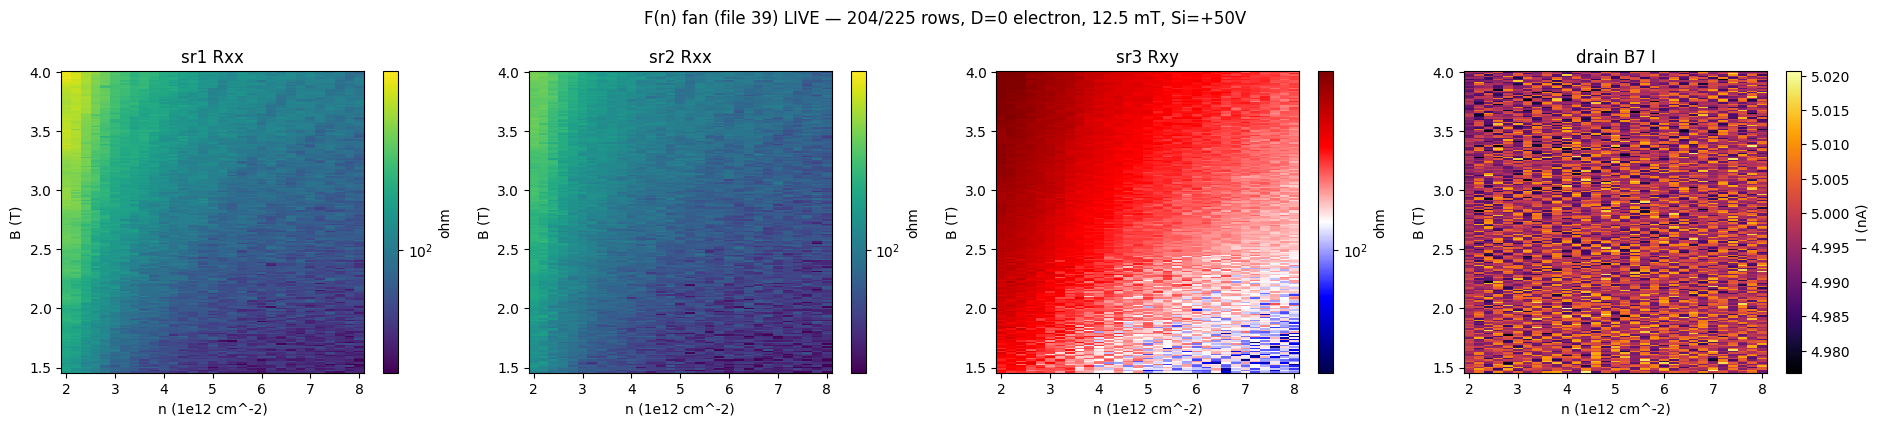

In [100]:
# LIVE F(n) fan view — re-run to refresh as rows land.
import os, scipy.constants as cst
C_TG=cst.epsilon_0*3.0/15.6e-9; C_BG=1.298*C_TG; N_OFF=-7.095e14
# find the F(n) fan run (latest with that comment), else latest run dir
fid=None
for d in sorted([int(x) for x in os.listdir(file_path) if x.isdigit()], reverse=True):
    if 'landau-fan-vti' in ' '.join(load_meta(d).get('comments', [])):
        fid=d; break
if fid is None:
    print("no landau-fan-vti run found yet"); 
else:
    m=load_meta(fid); ci={c:i for i,c in enumerate(m['columns'])}
    fn=f"{file_path}/{fid}/data.tsv.gz" if os.path.exists(f"{file_path}/{fid}/data.tsv.gz") else f"{file_path}/{fid}/data.tsv"
    raw=np.genfromtxt(fn, invalid_raise=False)   # tolerate a half-written last line
    raw=raw[~np.isnan(raw).any(axis=1)]
    nfast=31; nr=raw.shape[0]//nfast
    if nr<1:
        print(f"fan file {fid}: <1 row so far ({raw.shape[0]} pts)")
    else:
        g=raw[:nr*nfast].reshape(nr,nfast,-1); I_bias=5e-9
        B=g[:,0,ci['magnet_mag']]; n=np.linspace(2,8,nfast)   # 1e12 cm^-2 (D=0 line)
        print(f"fan file {fid}: {nr}/225 B-rows, B {B[0]:.2f}->{B[-1]:.2f} T; drain med {np.median(g[:,:,ci['sr0_X']]/-1e6)*1e9:.2f} nA")
        fig,ax=plt.subplots(1,4,figsize=(19,4.3))
        for k,(nm,col,cm) in enumerate([('sr1 Rxx','sr1_X','viridis'),('sr2 Rxx','sr2_X','viridis'),('sr3 Rxy','sr3_X','seismic')]):
            R=g[:,:,ci[col]]/I_bias; vm=np.percentile(np.abs(R),99) if R.size else 1
            im=ax[k].pcolormesh(n,B,R,shading='auto',cmap=cm, norm=mpl.colors.SymLogNorm(linthresh=1, vmin=25, vmax=750))
            fig.colorbar(im,ax=ax[k],label='ohm'); ax[k].set(xlabel='n (1e12 cm^-2)',ylabel='B (T)',title=nm)
        Im=g[:,:,ci['sr0_X']]/-1e6
        im=ax[3].pcolormesh(n,B,Im*1e9,shading='auto',cmap='inferno'); fig.colorbar(im,ax=ax[3],label='I (nA)')
        ax[3].set(xlabel='n (1e12 cm^-2)',ylabel='B (T)',title='drain B7 I')
        fig.suptitle(f'F(n) fan (file {fid}) LIVE — {nr}/225 rows, D=0 electron, 12.5 mT, Si=+50V'); plt.tight_layout(); plt.show()


## F(n) fan — R_xx linecuts (re-run to refresh)

Raw R_xx (sr1) sliced both ways: **fixed-density R_xx vs B** (the SdH traces — oscillations/beating visible directly) and **fixed-field R_xx vs n**. No FFT. Re-execute as the fan fills (B descends 4→1.2 T, so the fixed-n traces lengthen downward in field over time).

fan file 39: 204/225 rows, B 1.46-4.00 T -> 1/B span 0.434


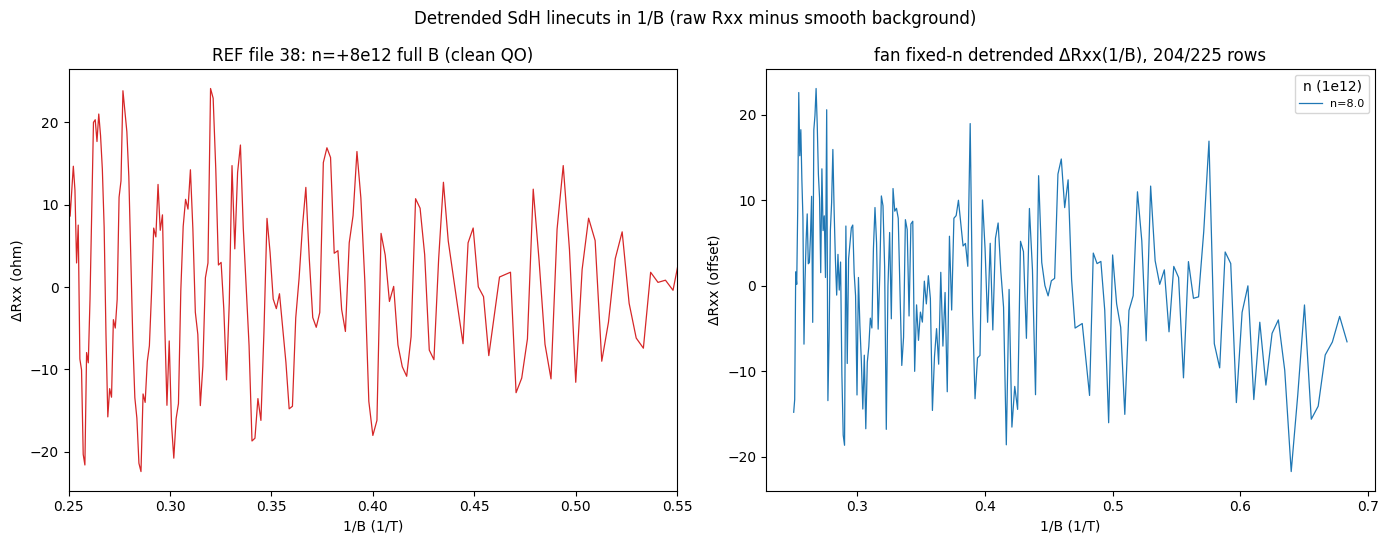

In [101]:
# Detrended SdH linecuts in 1/B (re-run to refresh). sr1 Rxx, no FFT.
import os
from scipy.ndimage import gaussian_filter1d
Ib=5e-9
def load(fid):
    m=load_meta(fid);ci={c:i for i,c in enumerate(m['columns'])}
    fn=f"{file_path}/{fid}/data.tsv.gz" if os.path.exists(f"{file_path}/{fid}/data.tsv.gz") else f"{file_path}/{fid}/data.tsv"
    raw=np.genfromtxt(fn,invalid_raise=False);return m,ci,raw[~np.isnan(raw).any(axis=1)]
fig,ax=plt.subplots(1,2,figsize=(14,5.5))
# Panel A: reference clean QO = file 38 (n=+8e12, full B 0->4 T)
m,ci,d=load(38);B=d[:,ci['magnet_mag']];sel=B>0.6;x=1/B[sel];o=np.argsort(x);x=x[o]
R=(d[sel,ci['sr1_X']]/Ib)[o];osc=R-gaussian_filter1d(R,18)
ax[0].plot(x,osc,lw=.9,color='C3')
ax[0].set(xlabel='1/B (1/T)',ylabel='ΔRxx (ohm)',title='REF file 38: n=+8e12 full B (clean QO)')
ax[0].set_xlim(0.25, 0.55)

# Panel B: fan fixed-density detrended in 1/B, waterfall
fid=None
for dd in sorted([int(x) for x in os.listdir(file_path) if x.isdigit()],reverse=True):
    if 'landau-fan-vti' in ' '.join(load_meta(dd).get('comments',[])): fid=dd;break
m,ci,raw=load(fid);nfast=31;nr=raw.shape[0]//nfast;g=raw[:nr*nfast].reshape(nr,nfast,-1)
B=g[:,0,ci['magnet_mag']];n=np.linspace(2,8,nfast);xb=1/B;ob=np.argsort(xb);xb=xb[ob]
print(f"fan file {fid}: {nr}/225 rows, B {B.min():.2f}-{B.max():.2f} T -> 1/B span {xb.max()-xb.min():.3f}")
off=0;sig=max(3,nr//6)
# for j in [30,23,15,7,0]:
for j in [30]:    
    R=(g[:,j,ci['sr1_X']]/Ib)[ob];osc=R-gaussian_filter1d(R,sig)
    ax[1].plot(xb,osc+off,lw=.9,label=f'n={n[j]:.1f}');off+=ax[1].get_ylim()[1]*0+ (np.nanstd(osc)*4 if np.isfinite(np.nanstd(osc)) else 5)
ax[1].set(xlabel='1/B (1/T)',ylabel='ΔRxx (offset)',title=f'fan fixed-n detrended ΔRxx(1/B), {nr}/225 rows')
ax[1].legend(fontsize=8,title='n (1e12)')
fig.suptitle('Detrended SdH linecuts in 1/B (raw Rxx minus smooth background)');plt.tight_layout();plt.show()



## F(n) by eye — detrended ΔR_xx(1/B) waterfall vs density (re-run to refresh)

Raw R_xx, background-subtracted, plotted vs 1/B for ~11 densities (n increases upward). No FFT. Shows QO at every density and the oscillation frequency (period in 1/B) tracking with n — the F(n) signal directly. Watch for the slow second-tone modulation persisting across density (the 2nd Fermi surface). Re-run as the fan fills toward B=1.2 T.

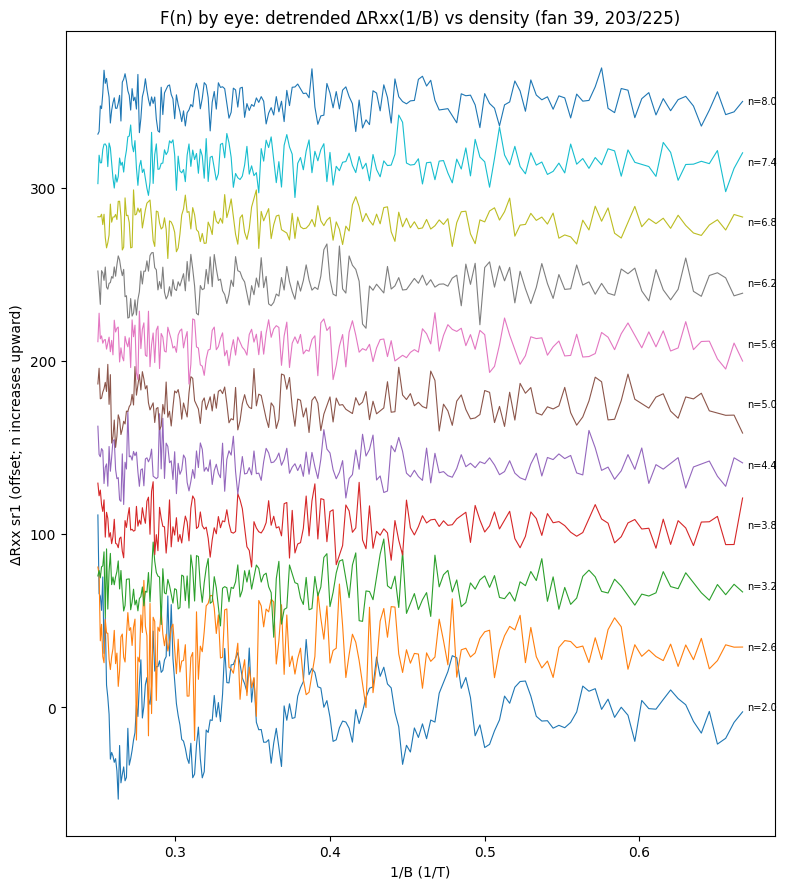

203/225 rows; QO present across density, period (F) scales with n


In [99]:
# F(n) by eye — detrended ΔRxx(1/B) waterfall across density (re-run to refresh). No FFT.
import os
from scipy.ndimage import gaussian_filter1d
fid=None
for d in sorted([int(x) for x in os.listdir(file_path) if x.isdigit()],reverse=True):
    if 'landau-fan-vti' in ' '.join(load_meta(d).get('comments',[])): fid=d;break
m=load_meta(fid);ci={c:i for i,c in enumerate(m['columns'])}
fn=f"{file_path}/{fid}/data.tsv.gz" if os.path.exists(f"{file_path}/{fid}/data.tsv.gz") else f"{file_path}/{fid}/data.tsv"
raw=np.genfromtxt(fn,invalid_raise=False);raw=raw[~np.isnan(raw).any(axis=1)]
nfast=31;nr=raw.shape[0]//nfast;g=raw[:nr*nfast].reshape(nr,nfast,-1)
B=g[:,0,ci['magnet_mag']];n=np.linspace(2,8,nfast);Ib=5e-9
sel=B>=1.5;x=1/B[sel];o=np.argsort(x);x=x[o]
fig,ax=plt.subplots(figsize=(8,9));off=0
for j in range(0,nfast,3):
    R=(g[sel,j,ci['sr1_X']]/Ib)[o];osc=R-gaussian_filter1d(R,10)
    ax.plot(x,osc+off,lw=.8); ax.text(x.max()*1.004,off,f'n={n[j]:.1f}',fontsize=7,va='center'); off+=35
ax.set(xlabel='1/B (1/T)',ylabel='ΔRxx sr1 (offset; n increases upward)',title=f'F(n) by eye: detrended ΔRxx(1/B) vs density (fan {fid}, {nr}/225)')
plt.tight_layout();plt.show()
print(f'{nr}/225 rows; QO present across density, period (F) scales with n')


## F(n) Onsager map — |FFT|(n,F) [the decisive view]

Per-column SdH FFT (B∈[1.2,4] T) stacked into |FFT| vs (n, F); Fermi-surface branches show as bright ridges. **Result: the dominant tone tracks the full-density line n·h/4e across n=2→8×10¹² on both channels; no clean second branch on a distinct Onsager curve.** → a single Fermi surface carrying the full density, **consistent-with ABC** — the one-density 'two-tone' hint does NOT survive as an n-tracking second pocket. Caveats: noisy above n~6; electron side only; harmonic/stability + hole-side + LK-mass would firm it.

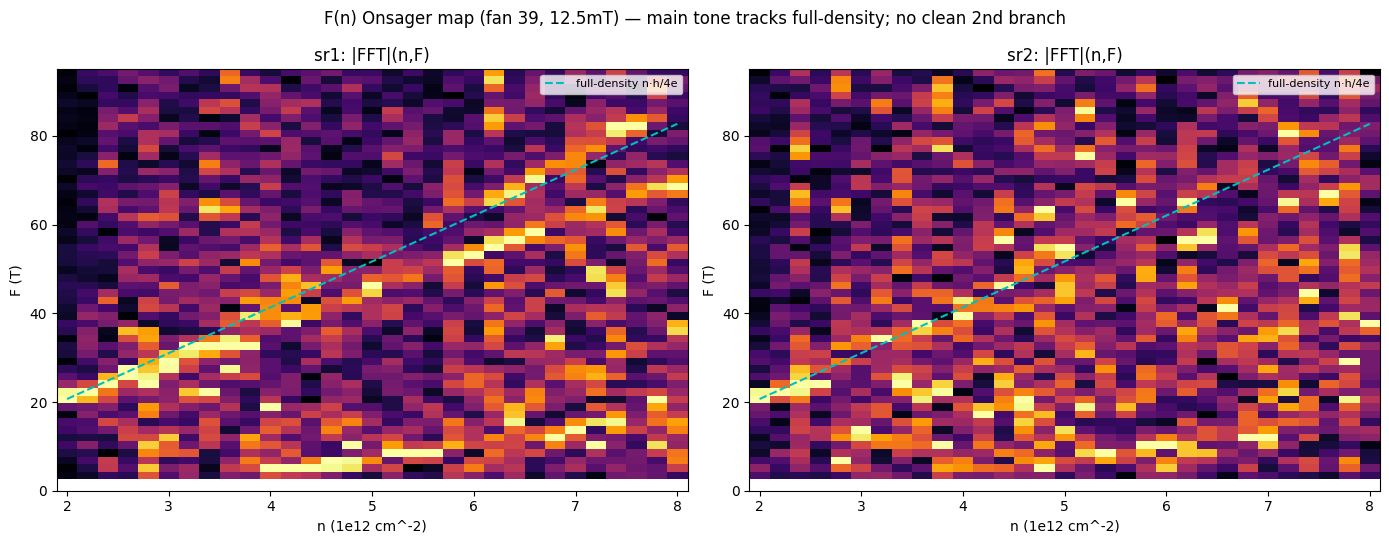

225/225 rows. Main ridge tracks n·h/4e (single full-density pocket -> consistent-with ABC); no resolved 2nd Onsager branch.


In [102]:
# F(n) Onsager map — |FFT|(n,F) per column. Branches = bright ridges. (re-run to refresh)
import os
fid=None
for d in sorted([int(x) for x in os.listdir(file_path) if x.isdigit()],reverse=True):
    if 'landau-fan-vti' in ' '.join(load_meta(d).get('comments',[])): fid=d;break
m=load_meta(fid);ci={c:i for i,c in enumerate(m['columns'])}
fn=f"{file_path}/{fid}/data.tsv.gz" if os.path.exists(f"{file_path}/{fid}/data.tsv.gz") else f"{file_path}/{fid}/data.tsv"
raw=np.genfromtxt(fn,invalid_raise=False);raw=raw[~np.isnan(raw).any(axis=1)]
nfast=31;nr=raw.shape[0]//nfast;g=raw[:nr*nfast].reshape(nr,nfast,-1)
B=g[:,0,ci['magnet_mag']];n=np.linspace(2,8,nfast);Ib=5e-9
F_lutt=np.abs(n*1e16)*6.62607e-34/(4*1.602177e-19)
def colfft(col,Blo,Bhi,N=8192):
    sel=(B>=Blo)&(B<=Bhi);x=1/B[sel];o=np.argsort(x);xs=x[o];SP=[]
    for j in range(nfast):
        r=(g[sel,j,ci[col]]/Ib)[o];xu=np.linspace(xs.min(),xs.max(),N);ru=np.interp(xu,xs,r)
        ru=ru-np.polyval(np.polyfit(xu,ru,6),xu);SP.append(np.abs(np.fft.rfft(ru*np.hanning(N))))
    Fa=np.fft.rfftfreq(N,d=xu[1]-xu[0]);return Fa,np.array(SP)
fig,ax=plt.subplots(1,2,figsize=(14,5.5))
for p,(col,lab) in enumerate([('sr1_X','sr1'),('sr2_X','sr2')]):
    Fa,SP=colfft(col,1.2,4.0);k=(Fa>3)&(Fa<95);Fk=Fa[k];img=SP[:,k];img=img/img.max(axis=1,keepdims=True)
    ax[p].pcolormesh(n,Fk,img.T,shading='auto',cmap='inferno')
    ax[p].plot(n,F_lutt,'c--',lw=1.5,label='full-density n·h/4e')
    ax[p].set(xlabel='n (1e12 cm^-2)',ylabel='F (T)',title=f'{lab}: |FFT|(n,F)');ax[p].legend(fontsize=8);ax[p].set_ylim(0,95)
fig.suptitle(f'F(n) Onsager map (fan {fid}, 12.5mT) — main tone tracks full-density; no clean 2nd branch');plt.tight_layout();plt.show()
print(f'{nr}/225 rows. Main ridge tracks n·h/4e (single full-density pocket -> consistent-with ABC); no resolved 2nd Onsager branch.')


# Updated stacking call — QC0426 (after resolution fixes + F(n) fan)

*Supersedes the first call (cells 14–16, "cannot tell — resolution-limited"). The first call was on data taken at 2 mV lock-in sensitivity (coarse ADC digitization) and 50 mT field steps (main-tone aliasing). Two fixes this session — voltage sensitivity 2 mV→200 µV and field sampling 50→12.5 mT — gave clean, eye-visible QO and a usable F(n) fan. (Mid-session the drain contact T7 died under high |n| + Si=+50 V; recovered by swapping drain T7→B7, device otherwise healthy, 9/15 contacts alive.)*

## 1. Per-region verdict (STYLE strength scale)
Region: main Hall bar, **electron side** (n = +2→+8×10¹²), D=0, drain B7.
- **sr1 (T3–T4): ABC — weak-to-moderate** (consistent-with a single full-density Fermi surface; no second Onsager-tracking branch).
- **sr2 (B4–B5): ABC — weak-to-moderate** (same; channels agree).
- **Hole side: not measured at this resolution → no verdict** (band-structure prior actually favors the hole side for a resolvable ML tone — a gap).

## 2. Evidence
- **Clean SdH QO** at 200 µV / 12.5 mT — eye-visible, ΔR_xx ~±20 Ω at B>1.5 T (ana cells 47, 50).
- **F(n) Onsager map (file 39, cells 52–53): the dominant tone tracks the full-density line F = n·h/4e across n = 2→8×10¹² on both channels; no clean second branch on a distinct Onsager curve.** → one Fermi surface carrying the full Luttinger density.
- **The one-density "two-tone" hint did not survive F(n)**: file 38 (n=+8×10¹²) showed a ~69 T tone + a ~16 T tone summing to ≈ full density (looked ABA), but the second peak does **not** track its own Onsager curve with n → it is a harmonic / second-region / window artifact, **not** a Fermi surface. F(n) was the decisive test.
- **Hall lever-arm** (n_Hall/n_gate = 0.95, cell 17–18) → absolute density scale confirmed to ~10 %, so "tracks full-density" rests on a sound scale.
- **(n,D) calibration** data-grade (c_bg/c_tg = 1.298, file 1).

## 3. Confidence + hedges
**Weak-to-moderate ABC lean.** Hedges:
- The *big* tone is intrinsically near-degenerate (ABC-single ≈ ABA-BL ≈ full density). The true discriminator is the *small* ML tone, which we do **not** cleanly resolve; its **absence** as a tracking branch leans ABC, but absence is weaker than presence — the ML tone could sit below our amplitude/resolution floor (T_e ≈ 8 K damping; δF ≈ 1.7 T; onset ≈ 1.2 T).
- **Electron side only**; hole side not measured at 12.5 mT.
- F(n) map **noisy above n ~ 6×10¹²**; per-column peak-pick unreliable → relied on the 2D |FFT| ridge.
- Single region (2 pairs agree); no mosaic survey at this resolution.
- **No LK-mass split** (`temperature-dependence` blocklisted) — the decisive 1-band-vs-2-band cross-check was not done.

## 4. What would firm the call
- **Hole-side fan at 12.5 mT** + per-channel triage (the band-structure prior for a resolvable ML tone).
- **Harmonic / FFT-stability audit** of the low-F weight + a proper ridge-tracking F(n) extraction.
- **LK-mass split** (`temperature-dependence` Flavor B; blocklisted here) — two masses → two bands (ABA), one → one (ABC). The decisive cross-check.
- High-field **Streda/Chern offset** as an independent complement; lower T / higher mobility to drop below the ML cyclotron gap.

## 5. Bottom line
**Consistent-with ABC (single full-density Fermi surface) — weak-to-moderate**, a real improvement over the prior resolution-limited "cannot tell." The dominant carriers occupy one pocket carrying the full Luttinger density, with no second Onsager-tracking branch resolved across n. **ABA is not decisively excluded** (the small ML discriminator remains below clean resolution, and ABA-BL ≈ full-density within our noise). So this is a *lean*, not a decisive call; the honest deciding tests (hole-side fan + LK mass at this resolution) are next-session items. Per the contract: a confident binary call is still not warranted on feature-level evidence — **"weak ABC lean, ABA not excluded"** is the calibrated statement.

*Method note (the session's main scientific lesson): the original "cannot tell" was never about the physics — it was instrumental resolution. Lock-in sensitivity matched to I_bias×R (200 µV, not 2 mV) and field sampling fine enough to keep the high-n main tone Nyquist-clean (12.5 mT, not 50 mT) were both required before SdH/F(n) became interpretable. And one density can mislead (file 38 looked ABA); F(n) is what discriminates.*
